<a href="https://colab.research.google.com/github/yudhiardiyanto/TUGT-CONTEXTAWARE-CNN-BiLSTM/blob/main/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projection Size Experiment and Context Ablation for Multimodal Fall-Risk Prediction



In [ ]:
# ============================================================
# STEP 1: MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ============================================================
# STEP 2: IMPORT LIBRARIES
# ============================================================

import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Model, layers, regularizers

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    ConfusionMatrixDisplay,
)

from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)

TensorFlow : 2.20.0
NumPy      : 2.0.2
Pandas     : 2.2.2


In [ ]:
# ============================================================
# STEP 3: OLD CONFIGURATION, SEPARATE OUTPUT PATHS, AND SEEDS
# ============================================================

DATA_PATH = Path(
    "/content/drive/MyDrive/"
    "DATASET-TUG-CONTEXT/"
    "Results/"
    "Final_Context_Model_18-7-2026_Multimodal_Fall_Risk/"
    "Tables/"
    "multimodal_fall_risk_dataset.csv"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "DATASET-TUG-CONTEXT/"
    "Results/"
    "30_7_2026_Projection_Size_Context_Ablation_LOSO_OOF_SHAP"
)

# Separate result folders.
PROJECTION_DIR = OUTPUT_DIR / "01_Projection_Size_Experiment"
BASELINE_DIR = OUTPUT_DIR / "02_Baseline_Without_Context"
PROPOSED_DIR = OUTPUT_DIR / "03_Proposed_With_Context"
COMPARISON_DIR = OUTPUT_DIR / "04_Context_Ablation_Comparison"
SHAP_DIR = OUTPUT_DIR / "05_OOF_SHAP_Proposed_Model"

PROJECTION_TABLE_DIR = PROJECTION_DIR / "Tables"
PROJECTION_FIGURE_DIR = PROJECTION_DIR / "Figures"
PROJECTION_WEIGHT_DIR = PROJECTION_DIR / "Fold_Weights"

BASELINE_TABLE_DIR = BASELINE_DIR / "Tables"
BASELINE_FIGURE_DIR = BASELINE_DIR / "Figures"

PROPOSED_TABLE_DIR = PROPOSED_DIR / "Tables"
PROPOSED_FIGURE_DIR = PROPOSED_DIR / "Figures"
PROPOSED_WEIGHT_DIR = PROPOSED_DIR / "Fold_Weights"

COMPARISON_TABLE_DIR = COMPARISON_DIR / "Tables"
COMPARISON_FIGURE_DIR = COMPARISON_DIR / "Figures"

SHAP_TABLE_DIR = SHAP_DIR / "Tables"
SHAP_FIGURE_DIR = SHAP_DIR / "Figures"

ALL_DIRECTORIES = [
    OUTPUT_DIR,
    PROJECTION_DIR,
    BASELINE_DIR,
    PROPOSED_DIR,
    COMPARISON_DIR,
    SHAP_DIR,
    PROJECTION_TABLE_DIR,
    PROJECTION_FIGURE_DIR,
    PROJECTION_WEIGHT_DIR,
    BASELINE_TABLE_DIR,
    BASELINE_FIGURE_DIR,
    PROPOSED_TABLE_DIR,
    PROPOSED_FIGURE_DIR,
    PROPOSED_WEIGHT_DIR,
    COMPARISON_TABLE_DIR,
    COMPARISON_FIGURE_DIR,
    SHAP_TABLE_DIR,
    SHAP_FIGURE_DIR,
]

for directory in ALL_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)

PROJECTION_SIZES = [64, 32, 16, 8]
RANDOM_SEEDS = [42, 123, 2026]
PRIMARY_SEED = 42

THRESHOLD = 0.50
VALIDATION_SIZE = 0.20

EPOCHS = 300
BATCH_SIZE = 8
PATIENCE = 25
REDUCE_LR_PATIENCE = 8
DROPOUT_RATE = 0.30
LEARNING_RATE = 1e-3
L2_RATE = 1e-4

SHAP_BACKGROUND_SIZE = 8
SHAP_NSAMPLES = 300

BASELINE_MODEL_NAME = "MLP_Dense8_Duration_Physiological"
PROPOSED_MODEL_NAME = "MLP_Dense8_Context_Duration_Physiological"

def set_all_seeds(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

set_all_seeds(PRIMARY_SEED)

print("=" * 72)
print("EXPERIMENT CONFIGURATION")
print("=" * 72)
print("Projection sizes :", PROJECTION_SIZES)
print("Random seeds     :", RANDOM_SEEDS)
print("Primary seed     :", PRIMARY_SEED)
print("Threshold        :", THRESHOLD)
print("Output directory :", OUTPUT_DIR)
print("=" * 72)

EXPERIMENT CONFIGURATION
Projection sizes : [64, 32, 16, 8]
Random seeds     : [42, 123, 2026]
Primary seed     : 42
Threshold        : 0.5
Output directory : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/30_7_2026_Projection_Size_Context_Ablation_LOSO_OOF_SHAP


In [ ]:
# ============================================================
# STEP 3: CONFIGURATION, OUTPUT DIRECTORIES, AND RANDOM SEEDS
# ============================================================

import os
import random

from pathlib import Path

import numpy as np
import tensorflow as tf


# ------------------------------------------------------------
# 1. DATASET PATH
# ------------------------------------------------------------

DATA_PATH = Path(
    "/content/drive/MyDrive/"
    "DATASET-TUG-CONTEXT/"
    "Results/"
    "Final_Context_Model_18-7-2026_Multimodal_Fall_Risk/"
    "Tables/"
    "multimodal_fall_risk_dataset.csv"
)


# ------------------------------------------------------------
# 2. MAIN OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "DATASET-TUG-CONTEXT/"
    "Results/"
    "Projection_Size_Context_Ablation_Best_Model_OOF_SHAP"
)


# ------------------------------------------------------------
# 3. MAIN EXPERIMENT DIRECTORIES
# ------------------------------------------------------------

PROJECTION_DIR = (
    OUTPUT_DIR
    / "01_Projection_Size_Experiment"
)

BASELINE_DIR = (
    OUTPUT_DIR
    / "02_Baseline_Without_Context"
)

PROPOSED_DIR = (
    OUTPUT_DIR
    / "03_Context_Aware_Model"
)

COMPARISON_DIR = (
    OUTPUT_DIR
    / "04_Context_Ablation_Comparison"
)

SHAP_DIR = (
    OUTPUT_DIR
    / "05_OOF_SHAP_Best_Model"
)


# ------------------------------------------------------------
# 4. PROJECTION-EXPERIMENT DIRECTORIES
# ------------------------------------------------------------

PROJECTION_TABLE_DIR = (
    PROJECTION_DIR
    / "Tables"
)

PROJECTION_FIGURE_DIR = (
    PROJECTION_DIR
    / "Figures"
)

PROJECTION_WEIGHT_DIR = (
    PROJECTION_DIR
    / "Fold_Weights"
)


# ------------------------------------------------------------
# 5. BASELINE DIRECTORIES
#
# Model:
# Dense Projection
# + Physiological
# + Phase Duration
# ------------------------------------------------------------

BASELINE_TABLE_DIR = (
    BASELINE_DIR
    / "Tables"
)

BASELINE_FIGURE_DIR = (
    BASELINE_DIR
    / "Figures"
)

BASELINE_WEIGHT_DIR = (
    BASELINE_DIR
    / "Fold_Weights"
)


# ------------------------------------------------------------
# 6. CONTEXT-AWARE MODEL DIRECTORIES
#
# Model:
# Dense Projection
# + Context
# + Physiological
# + Phase Duration
# ------------------------------------------------------------

PROPOSED_TABLE_DIR = (
    PROPOSED_DIR
    / "Tables"
)

PROPOSED_FIGURE_DIR = (
    PROPOSED_DIR
    / "Figures"
)

PROPOSED_WEIGHT_DIR = (
    PROPOSED_DIR
    / "Fold_Weights"
)


# ------------------------------------------------------------
# 7. COMPARISON DIRECTORIES
# ------------------------------------------------------------

COMPARISON_TABLE_DIR = (
    COMPARISON_DIR
    / "Tables"
)

COMPARISON_FIGURE_DIR = (
    COMPARISON_DIR
    / "Figures"
)


# ------------------------------------------------------------
# 8. SHAP DIRECTORIES
# ------------------------------------------------------------

SHAP_TABLE_DIR = (
    SHAP_DIR
    / "Tables"
)

SHAP_FIGURE_DIR = (
    SHAP_DIR
    / "Figures"
)

SHAP_WEIGHT_DIR = (
    SHAP_DIR
    / "Selected_Fold_Weights"
)


# ------------------------------------------------------------
# 9. CREATE ALL DIRECTORIES
# ------------------------------------------------------------

ALL_DIRECTORIES = [
    OUTPUT_DIR,

    PROJECTION_DIR,
    PROJECTION_TABLE_DIR,
    PROJECTION_FIGURE_DIR,
    PROJECTION_WEIGHT_DIR,

    BASELINE_DIR,
    BASELINE_TABLE_DIR,
    BASELINE_FIGURE_DIR,
    BASELINE_WEIGHT_DIR,

    PROPOSED_DIR,
    PROPOSED_TABLE_DIR,
    PROPOSED_FIGURE_DIR,
    PROPOSED_WEIGHT_DIR,

    COMPARISON_DIR,
    COMPARISON_TABLE_DIR,
    COMPARISON_FIGURE_DIR,

    SHAP_DIR,
    SHAP_TABLE_DIR,
    SHAP_FIGURE_DIR,
    SHAP_WEIGHT_DIR,
]

for directory in ALL_DIRECTORIES:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 10. PROJECTION-SIZE CONFIGURATION
# ------------------------------------------------------------

PROJECTION_SIZES = [
    64,
    32,
    16,
    8,
]


# ------------------------------------------------------------
# 11. RANDOM-SEED CONFIGURATION
# ------------------------------------------------------------

RANDOM_SEEDS = [
    42,
    123,
    2026,
]

PRIMARY_SEED = 42


# ------------------------------------------------------------
# 12. TRAINING CONFIGURATION
# ------------------------------------------------------------

THRESHOLD = 0.50

VALIDATION_SIZE = 0.20

EPOCHS = 300

BATCH_SIZE = 8

PATIENCE = 25

REDUCE_LR_PATIENCE = 8

DROPOUT_RATE = 0.30

LEARNING_RATE = 1e-3

L2_RATE = 1e-4


# ------------------------------------------------------------
# 13. SHAP CONFIGURATION
# ------------------------------------------------------------

SHAP_BACKGROUND_SIZE = 8

SHAP_NSAMPLES = 300


# ------------------------------------------------------------
# 14. MODEL NAMES
# ------------------------------------------------------------

BASELINE_MODEL_NAME = (
    "MLP_Dense8_Duration_Physiological"
)

PROPOSED_MODEL_NAME = (
    "MLP_Dense8_Context_Duration_Physiological"
)


# ------------------------------------------------------------
# 15. REPRODUCIBILITY FUNCTION
# ------------------------------------------------------------

def set_all_seeds(
    seed: int,
) -> None:
    """
    Set random seeds for Python, NumPy, and TensorFlow.
    """

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    tf.keras.utils.set_random_seed(
        seed
    )

    try:
        tf.config.experimental.enable_op_determinism()

    except Exception:
        pass


set_all_seeds(
    PRIMARY_SEED
)


# ------------------------------------------------------------
# 16. CONFIGURATION AUDIT
# ------------------------------------------------------------

print("=" * 78)
print("EXPERIMENT CONFIGURATION")
print("=" * 78)

print(
    "Dataset path                  :",
    DATA_PATH,
)

print(
    "Output directory              :",
    OUTPUT_DIR,
)

print(
    "Projection sizes              :",
    PROJECTION_SIZES,
)

print(
    "Random seeds                  :",
    RANDOM_SEEDS,
)

print(
    "Primary seed                  :",
    PRIMARY_SEED,
)

print(
    "Decision threshold            :",
    THRESHOLD,
)

print(
    "Baseline weight directory     :",
    BASELINE_WEIGHT_DIR,
)

print(
    "Context-aware weight directory:",
    PROPOSED_WEIGHT_DIR,
)

print(
    "SHAP output directory         :",
    SHAP_DIR,
)

print("=" * 78)


# ------------------------------------------------------------
# 17. DIRECTORY VALIDATION
# ------------------------------------------------------------

missing_directories = [
    directory
    for directory in ALL_DIRECTORIES
    if not directory.exists()
]

if missing_directories:
    raise RuntimeError(
        "The following output directories "
        "could not be created:\n- "
        + "\n- ".join(
            str(directory)
            for directory in missing_directories
        )
    )

print(
    "Directory validation          : PASSED"
)

print(
    "Total output directories      :",
    len(ALL_DIRECTORIES),
)

print("=" * 78)

EXPERIMENT CONFIGURATION
Dataset path                  : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model_18-7-2026_Multimodal_Fall_Risk/Tables/multimodal_fall_risk_dataset.csv
Output directory              : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP
Projection sizes              : [64, 32, 16, 8]
Random seeds                  : [42, 123, 2026]
Primary seed                  : 42
Decision threshold            : 0.5
Baseline weight directory     : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/02_Baseline_Without_Context/Fold_Weights
Context-aware weight directory: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/03_Context_Aware_Model/Fold_Weights
SHAP output directory         : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_B

In [ ]:
# ============================================================
# STEP 4: LOAD AND VALIDATE THE SUBJECT-LEVEL DATASET
# ============================================================

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset was not found: {DATA_PATH}\n"
        "Check the dataset location in Google Drive."
    )

df = pd.read_csv(DATA_PATH)

SKELETON_COLS = [f"skel_emb_{i:03d}" for i in range(64)]

CONTEXT_COLS = [
    "temperature",
    "humidity",
    "light_intensity",
    "pressure",
]

PHYSIO_COLS = [
    "age",
    "bmi",
    "body_temperature",
    "mean_spo2",
    "mean_heart_rate",
]

DURATION_COLS = [
    "duration_STS",
    "duration_WO",
    "duration_TR",
    "duration_WI",
    "duration_STTS",
]

TARGET_COL = "fall_risk"
SUBJECT_COL = "subject"

RAW_FEATURE_COLS = (
    SKELETON_COLS
    + CONTEXT_COLS
    + PHYSIO_COLS
    + DURATION_COLS
)

required_cols = [SUBJECT_COL, TARGET_COL] + RAW_FEATURE_COLS
missing_cols = [
    column
    for column in required_cols
    if column not in df.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

if df[required_cols].isna().any().any():
    missing = df[required_cols].isna().sum()
    raise ValueError(
        "The dataset contains missing values:\n"
        f"{missing[missing > 0]}"
    )

if df[SUBJECT_COL].duplicated().any():
    duplicated = df.loc[
        df[SUBJECT_COL].duplicated(keep=False),
        SUBJECT_COL,
    ].tolist()
    raise ValueError(f"Duplicated subjects: {duplicated}")

label_mapping = {
    "LOW/NO": 0,
    "HIGH": 1,
}

unknown_labels = set(df[TARGET_COL].unique()) - set(label_mapping)

if unknown_labels:
    raise ValueError(f"Unrecognized labels: {unknown_labels}")

X_skeleton = df[SKELETON_COLS].to_numpy(dtype=np.float32)
X_context = df[CONTEXT_COLS].to_numpy(dtype=np.float32)
X_physio = df[PHYSIO_COLS].to_numpy(dtype=np.float32)
X_duration = df[DURATION_COLS].to_numpy(dtype=np.float32)

X_raw = df[RAW_FEATURE_COLS].to_numpy(dtype=np.float32)

y = df[TARGET_COL].map(label_mapping).to_numpy(dtype=np.int32)
subjects = df[SUBJECT_COL].astype(str).to_numpy()

assert X_skeleton.shape[1] == 64
assert X_context.shape[1] == 4
assert X_physio.shape[1] == 5
assert X_duration.shape[1] == 5
assert X_raw.shape[1] == 78
assert len(np.unique(subjects)) == len(subjects)

print("=" * 72)
print("DATASET AUDIT")
print("=" * 72)
print("Subjects                :", len(subjects))
print("LOW/NO                  :", int((y == 0).sum()))
print("HIGH                    :", int((y == 1).sum()))
print("Skeleton embedding      :", X_skeleton.shape)
print("Context                 :", X_context.shape)
print("Physiological           :", X_physio.shape)
print("Phase duration          :", X_duration.shape)
print("Original multimodal     :", X_raw.shape)
print("=" * 72)

display(
    df[
        [SUBJECT_COL, TARGET_COL]
        + CONTEXT_COLS
        + PHYSIO_COLS
        + DURATION_COLS
    ].head()
)

DATASET AUDIT
Subjects                : 30
LOW/NO                  : 10
HIGH                    : 20
Skeleton embedding      : (30, 64)
Context                 : (30, 4)
Physiological           : (30, 5)
Phase duration          : (30, 5)
Original multimodal     : (30, 78)


,subject,fall_risk,temperature,humidity,light_intensity,pressure,age,bmi,body_temperature,mean_spo2,mean_heart_rate,duration_STS,duration_WO,duration_TR,duration_WI,duration_STTS
0,subject01,HIGH,29.783459,64.625564,103.417293,1004.541729,64.0,24.02,36.8,98.5,70.0,1.280,5.568,5.312,3.952,5.423
1,subject02,HIGH,29.801667,65.177667,94.821333,1004.365333,68.0,15.24,36.8,98.0,55.5,1.216,6.208,3.840,5.136,5.312
2,subject03,HIGH,29.044000,75.988667,292.535333,1010.021333,60.0,22.72,36.0,98.5,69.5,1.760,2.704,2.992,2.528,3.536
3,subject04,LOW/NO,29.221333,75.703333,253.390000,1010.026000,60.0,18.37,36.0,99.0,77.5,0.976,2.992,2.736,2.432,2.964
4,subject05,HIGH,29.746667,63.684667,73.846333,1003.881000,67.0,24.69,36.8,98.5,92.0,0.944,3.712,2.528,4.224,3.248


In [ ]:
# ============================================================
# STEP 5: HELPER FUNCTIONS FOR LOSO, METRICS, AND INPUT PACKING
# ============================================================

def make_inner_validation_split(
    outer_train_idx: np.ndarray,
    y_all: np.ndarray,
    seed: int,
):
    outer_labels = y_all[outer_train_idx]

    inner_train_idx, val_idx = train_test_split(
        outer_train_idx,
        test_size=VALIDATION_SIZE,
        random_state=seed,
        stratify=outer_labels,
    )

    return inner_train_idx, val_idx


def calculate_binary_metrics(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold: float = THRESHOLD,
):
    y_true = np.asarray(y_true, dtype=np.int32)
    y_prob = np.asarray(y_prob, dtype=np.float64)
    y_pred = (y_prob >= threshold).astype(np.int32)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "specificity_low_no": (
            tn / (tn + fp) if (tn + fp) > 0 else np.nan
        ),
        "sensitivity_high": (
            tp / (tp + fn) if (tp + fn) > 0 else np.nan
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


def class_weight_dict(y_train: np.ndarray):
    classes = np.unique(y_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train,
    )

    return {
        int(class_label): float(weight)
        for class_label, weight in zip(classes, weights)
    }


def pack_model_inputs(
    skeleton_values,
    context_values,
    physio_values,
    duration_values,
    include_context: bool,
):
    if include_context:
        return [
            skeleton_values,
            context_values,
            physio_values,
            duration_values,
        ]

    return [
        skeleton_values,
        physio_values,
        duration_values,
    ]


def build_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=0,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=REDUCE_LR_PATIENCE,
            min_lr=1e-6,
            verbose=0,
        ),
    ]

In [ ]:
# ============================================================
# STEP 6: DEFINE THE PARAMETRIC MULTIMODAL MLP
#
# projection_dim:
# - 64, 32, 16, or 8 during the projection experiment.
# - selected projection (expected Dense-8) during ablation.
#
# include_context:
# - False: Dense projection + Physiological + Duration.
# - True : Dense projection + Context + Physiological + Duration.
# ============================================================

def build_multimodal_mlp_model(
    projection_dim: int,
    include_context: bool,
):
    tf.keras.backend.clear_session()

    skeleton_input = layers.Input(
        shape=(64,),
        name="skeleton_embedding_input",
    )

    physiological_input = layers.Input(
        shape=(5,),
        name="physiological_input",
    )

    duration_input = layers.Input(
        shape=(5,),
        name="phase_duration_input",
    )

    model_inputs = [
        skeleton_input,
        physiological_input,
        duration_input,
    ]

    projected_skeleton = layers.Dense(
        projection_dim,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name=f"skeleton_projection_dense_{projection_dim}",
    )(skeleton_input)

    projected_skeleton = layers.BatchNormalization(
        name=f"skeleton_projection_bn_{projection_dim}",
    )(projected_skeleton)

    projected_skeleton = layers.Dropout(
        DROPOUT_RATE,
        name=f"skeleton_projection_dropout_{projection_dim}",
    )(projected_skeleton)

    fusion_inputs = [
        projected_skeleton,
        physiological_input,
        duration_input,
    ]

    if include_context:
        context_input = layers.Input(
            shape=(4,),
            name="context_input",
        )
        model_inputs = [
            skeleton_input,
            context_input,
            physiological_input,
            duration_input,
        ]
        fusion_inputs = [
            projected_skeleton,
            context_input,
            physiological_input,
            duration_input,
        ]

    fusion = layers.Concatenate(
        name="multimodal_concatenation",
    )(fusion_inputs)

    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name="mlp_dense_64",
    )(fusion)

    x = layers.BatchNormalization(
        name="mlp_batch_normalization_64",
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="mlp_dropout_64",
    )(x)

    x = layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name="mlp_dense_32",
    )(x)

    x = layers.BatchNormalization(
        name="mlp_batch_normalization_32",
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="mlp_dropout_32",
    )(x)

    x = layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name="mlp_dense_16",
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="mlp_dropout_16",
    )(x)

    output = layers.Dense(
        1,
        activation="sigmoid",
        name="fall_risk_probability",
    )(x)

    configuration_name = (
        "with_context"
        if include_context
        else "without_context"
    )

    model = Model(
        inputs=model_inputs,
        outputs=output,
        name=(
            f"multimodal_mlp_dense_{projection_dim}_"
            f"{configuration_name}"
        ),
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE,
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
        ],
    )

    return model


# Verify dimensions and parameters.
for projection_dim in PROJECTION_SIZES:
    temp_model = build_multimodal_mlp_model(
        projection_dim=projection_dim,
        include_context=True,
    )
    print(
        f"Dense-{projection_dim:>2} | "
        f"Fusion input={projection_dim + 4 + 5 + 5:>2} | "
        f"Parameters={temp_model.count_params():,}"
    )

del temp_model
tf.keras.backend.clear_session()

Dense-64 | Fusion input=78 | Parameters=12,481
Dense-32 | Fusion input=46 | Parameters=8,225
Dense-16 | Fusion input=30 | Parameters=6,097
Dense- 8 | Fusion input=22 | Parameters=5,033


In [ ]:
# ============================================================
# STEP 7: PROJECTION SIZE EXPERIMENT
#
# Repeated LOSO for Dense-64, Dense-32, Dense-16, and Dense-8.
# The complete context-aware configuration is used consistently:
#
# Projected Skeleton + Context + Physiological + Phase Duration.
# ============================================================

loo = LeaveOneOut()

projection_prediction_rows = []
projection_metric_rows = []

for projection_dim in PROJECTION_SIZES:
    print("\n" + "#" * 92)
    print(f"PROJECTION SIZE EXPERIMENT: DENSE-{projection_dim}")
    print("#" * 92)

    for seed in RANDOM_SEEDS:
        set_all_seeds(seed)

        oof_probabilities = np.full(
            len(y),
            np.nan,
            dtype=np.float64,
        )

        for fold, (outer_train_idx, test_idx) in enumerate(
            loo.split(X_raw),
            start=1,
        ):
            fold_seed = seed + fold + projection_dim
            set_all_seeds(fold_seed)

            inner_train_idx, val_idx = make_inner_validation_split(
                outer_train_idx=outer_train_idx,
                y_all=y,
                seed=fold_seed,
            )

            skeleton_scaler = StandardScaler()
            context_scaler = StandardScaler()
            physio_scaler = StandardScaler()
            duration_scaler = StandardScaler()

            Xs_train = skeleton_scaler.fit_transform(
                X_skeleton[inner_train_idx]
            ).astype(np.float32)
            Xs_val = skeleton_scaler.transform(
                X_skeleton[val_idx]
            ).astype(np.float32)
            Xs_test = skeleton_scaler.transform(
                X_skeleton[test_idx]
            ).astype(np.float32)

            Xc_train = context_scaler.fit_transform(
                X_context[inner_train_idx]
            ).astype(np.float32)
            Xc_val = context_scaler.transform(
                X_context[val_idx]
            ).astype(np.float32)
            Xc_test = context_scaler.transform(
                X_context[test_idx]
            ).astype(np.float32)

            Xp_train = physio_scaler.fit_transform(
                X_physio[inner_train_idx]
            ).astype(np.float32)
            Xp_val = physio_scaler.transform(
                X_physio[val_idx]
            ).astype(np.float32)
            Xp_test = physio_scaler.transform(
                X_physio[test_idx]
            ).astype(np.float32)

            Xd_train = duration_scaler.fit_transform(
                X_duration[inner_train_idx]
            ).astype(np.float32)
            Xd_val = duration_scaler.transform(
                X_duration[val_idx]
            ).astype(np.float32)
            Xd_test = duration_scaler.transform(
                X_duration[test_idx]
            ).astype(np.float32)

            model = build_multimodal_mlp_model(
                projection_dim=projection_dim,
                include_context=True,
            )

            history = model.fit(
                pack_model_inputs(
                    Xs_train,
                    Xc_train,
                    Xp_train,
                    Xd_train,
                    include_context=True,
                ),
                y[inner_train_idx],
                validation_data=(
                    pack_model_inputs(
                        Xs_val,
                        Xc_val,
                        Xp_val,
                        Xd_val,
                        include_context=True,
                    ),
                    y[val_idx],
                ),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict(
                    y[inner_train_idx]
                ),
                callbacks=build_callbacks(),
                verbose=0,
            )

            probability = float(
                model.predict(
                    pack_model_inputs(
                        Xs_test,
                        Xc_test,
                        Xp_test,
                        Xd_test,
                        include_context=True,
                    ),
                    verbose=0,
                ).ravel()[0]
            )

            oof_probabilities[int(test_idx[0])] = probability

            del model
            tf.keras.backend.clear_session()
            gc.collect()

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                "Incomplete projection OOF predictions: "
                f"projection={projection_dim}, seed={seed}"
            )

        metrics = calculate_binary_metrics(y, oof_probabilities)
        oof_predictions = (
            oof_probabilities >= THRESHOLD
        ).astype(np.int32)

        projection_metric_rows.append({
            "projection_dim": projection_dim,
            "seed": seed,
            **metrics,
        })

        for subject_index in range(len(y)):
            projection_prediction_rows.append({
                "projection_dim": projection_dim,
                "seed": seed,
                "subject": subjects[subject_index],
                "true_label": int(y[subject_index]),
                "probability_high": float(
                    oof_probabilities[subject_index]
                ),
                "predicted_label": int(
                    oof_predictions[subject_index]
                ),
                "correct": int(
                    oof_predictions[subject_index]
                    == y[subject_index]
                ),
            })

projection_predictions_df = pd.DataFrame(
    projection_prediction_rows
)
projection_metrics_df = pd.DataFrame(
    projection_metric_rows
)

projection_predictions_df.to_csv(
    PROJECTION_TABLE_DIR / "Projection_Size_OOF_Predictions.csv",
    index=False,
)
projection_metrics_df.to_csv(
    PROJECTION_TABLE_DIR / "Projection_Size_Performance_By_Seed.csv",
    index=False,
)

display(projection_metrics_df)


############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-64
############################################################################################



############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-32
############################################################################################

############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-16
############################################################################################

############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-8
############################################################################################


,projection_dim,seed,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,64,42,0.275,0.551811,0.333333,0.275,0.291667,0.275,0.282297,0.1,0.45,1,9,11,9
1,64,123,0.595,0.785370,0.533333,0.475,0.475000,0.475,0.475000,0.3,0.65,3,7,7,13
2,64,2026,0.525,0.777522,0.433333,0.400,0.409502,0.400,0.400705,0.3,0.50,3,7,10,10
3,32,42,0.350,0.688876,0.333333,0.300,0.321429,0.300,0.305556,0.2,0.40,2,8,12,8
4,32,123,0.590,0.778576,0.600000,0.550,0.550000,0.550,0.550000,0.4,0.70,4,6,6,14
5,32,2026,0.565,0.739435,0.600000,0.525,0.528409,0.525,0.523810,0.3,0.75,3,7,5,15
6,16,42,0.575,0.711990,0.633333,0.625,0.613122,0.625,0.612221,0.6,0.65,6,4,7,13
7,16,123,0.535,0.735981,0.633333,0.575,0.579365,0.575,0.576380,0.4,0.75,4,6,5,15
8,16,2026,0.710,0.850569,0.633333,0.625,0.613122,0.625,0.612221,0.6,0.65,6,4,7,13
9,8,42,0.725,0.852354,0.700000,0.675,0.667464,0.675,0.670330,0.6,0.75,6,4,5,15


In [ ]:
# ============================================================
# STEP 8: SUMMARIZE AND SELECT THE BEST PROJECTION SIZE
# ============================================================

projection_metric_columns = [
    "roc_auc",
    "pr_auc",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "specificity_low_no",
    "sensitivity_high",
]

projection_summary_rows = []

for projection_dim in PROJECTION_SIZES:
    subset = projection_metrics_df[
        projection_metrics_df["projection_dim"]
        == projection_dim
    ]

    summary_row = {
        "projection_dim": projection_dim,
        "fusion_dimension": projection_dim + 4 + 5 + 5,
    }

    for metric in projection_metric_columns:
        summary_row[f"{metric}_mean"] = subset[metric].mean()
        summary_row[f"{metric}_std"] = subset[metric].std(ddof=1)

    projection_summary_rows.append(summary_row)

projection_summary_df = pd.DataFrame(
    projection_summary_rows
).sort_values(
    by=[
        "roc_auc_mean",
        "macro_f1_mean",
        "balanced_accuracy_mean",
        "projection_dim",
    ],
    ascending=[
        False,
        False,
        False,
        True,
    ],
).reset_index(drop=True)

SELECTED_PROJECTION_DIM = int(
    projection_summary_df.iloc[0]["projection_dim"]
)

projection_summary_df.to_csv(
    PROJECTION_TABLE_DIR / "Projection_Size_Summary.csv",
    index=False,
)

with open(
    PROJECTION_DIR / "Selected_Projection.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "selected_projection_dim": SELECTED_PROJECTION_DIM,
            "selection_metric": "mean pooled OOF ROC-AUC",
            "supporting_metrics": [
                "Macro F1",
                "Balanced Accuracy",
            ],
            "random_seeds": RANDOM_SEEDS,
        },
        file,
        indent=2,
    )

print("=" * 72)
print("SELECTED PROJECTION")
print("=" * 72)
print("Projection dimension :", SELECTED_PROJECTION_DIM)
print("=" * 72)

display(projection_summary_df)

SELECTED PROJECTION
Projection dimension : 8


,projection_dim,fusion_dimension,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,specificity_low_no_mean,specificity_low_no_std,sensitivity_high_mean,sensitivity_high_std
0,8,22,0.658333,0.059652,0.814856,0.040817,0.644444,0.050918,0.633333,0.038188,0.624922,0.037692,0.633333,0.038188,0.620053,0.043594,0.600000,0.10000,0.666667,0.104083
1,16,30,0.606667,0.091697,0.766180,0.074061,0.633333,0.000000,0.608333,0.028868,0.601870,0.019490,0.608333,0.028868,0.600274,0.020693,0.533333,0.11547,0.683333,0.057735
2,32,46,0.501667,0.131941,0.735629,0.044971,0.511111,0.153960,0.458333,0.137689,0.466613,0.126196,0.458333,0.137689,0.459788,0.134210,0.300000,0.10000,0.616667,0.189297
3,64,78,0.465000,0.168226,0.704901,0.132638,0.433333,0.100000,0.383333,0.101036,0.392056,0.092903,0.383333,0.101036,0.386001,0.097190,0.233333,0.11547,0.533333,0.104083


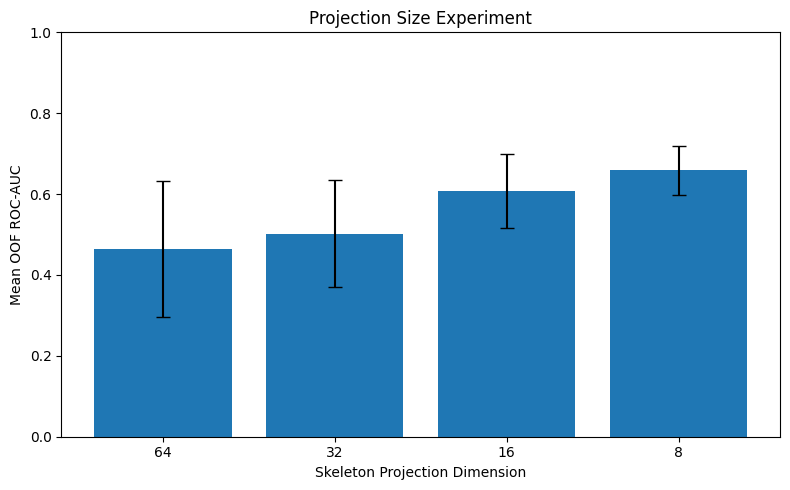

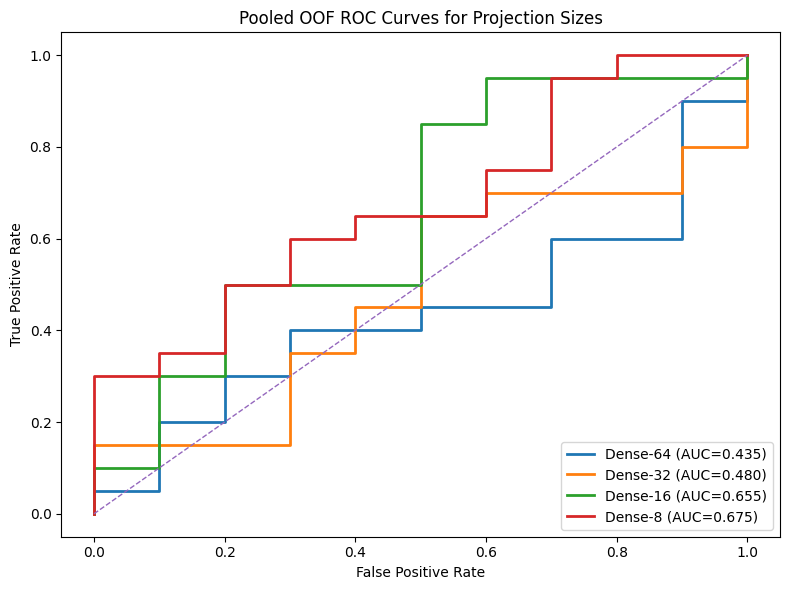

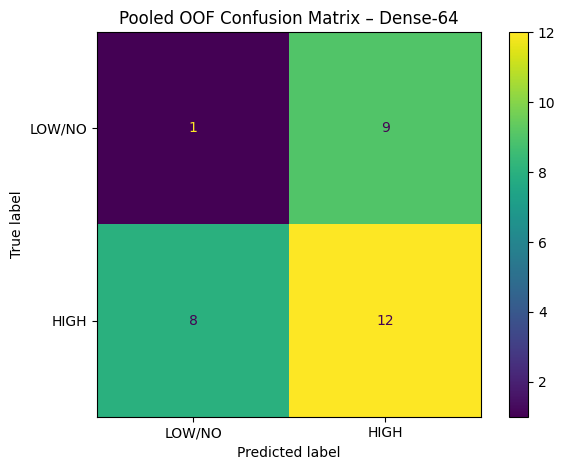

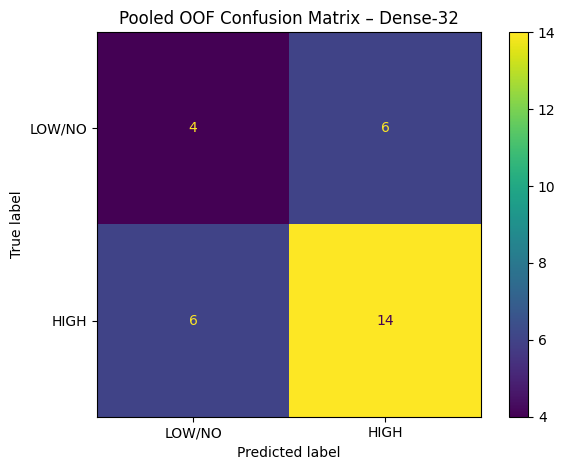

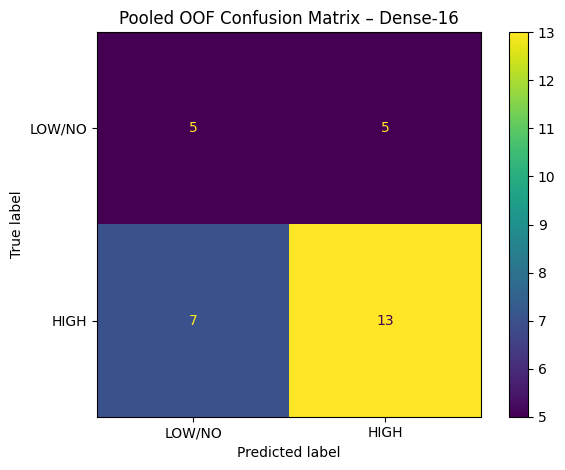

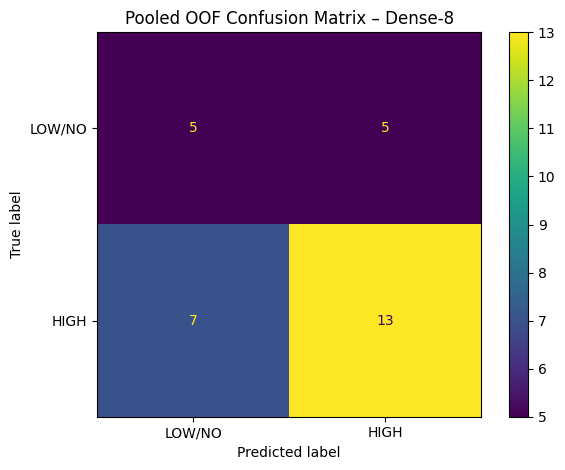

In [ ]:
# ============================================================
# STEP 9: VISUALIZE THE PROJECTION SIZE EXPERIMENT
# ============================================================

plot_df = projection_summary_df.sort_values(
    "projection_dim",
    ascending=False,
)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    plot_df["projection_dim"].astype(str),
    plot_df["roc_auc_mean"],
    yerr=plot_df["roc_auc_std"],
    capsize=5,
)
plt.xlabel("Skeleton Projection Dimension")
plt.ylabel("Mean OOF ROC-AUC")
plt.title("Projection Size Experiment")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(
    PROJECTION_FIGURE_DIR / "Projection_Size_ROC_AUC_Comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

plt.figure(figsize=(8, 6))

for projection_dim in PROJECTION_SIZES:
    subject_probability = (
        projection_predictions_df[
            projection_predictions_df["projection_dim"]
            == projection_dim
        ]
        .groupby(["subject", "true_label"], as_index=False)
        .agg(probability_high=("probability_high", "mean"))
        .set_index("subject")
        .loc[subjects]
    )

    fpr, tpr, _ = roc_curve(
        y,
        subject_probability["probability_high"].to_numpy(),
    )
    auc_value = roc_auc_score(
        y,
        subject_probability["probability_high"].to_numpy(),
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"Dense-{projection_dim} (AUC={auc_value:.3f})",
    )

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Pooled OOF ROC Curves for Projection Sizes")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    PROJECTION_FIGURE_DIR / "Projection_Size_Pooled_OOF_ROC_Curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

for projection_dim in PROJECTION_SIZES:
    subject_probability = (
        projection_predictions_df[
            projection_predictions_df["projection_dim"]
            == projection_dim
        ]
        .groupby(["subject", "true_label"], as_index=False)
        .agg(probability_high=("probability_high", "mean"))
        .set_index("subject")
        .loc[subjects]
    )

    predicted = (
        subject_probability["probability_high"].to_numpy()
        >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(y, predicted, labels=[0, 1])

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["LOW/NO", "HIGH"],
    )
    display_cm.plot(values_format="d")
    plt.title(f"Pooled OOF Confusion Matrix – Dense-{projection_dim}")
    plt.tight_layout()
    plt.savefig(
        PROJECTION_FIGURE_DIR
        / f"Confusion_Matrix_Dense_{projection_dim}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

# Context Ablation Study

Dua konfigurasi menggunakan **projection dimension terpilih** dan arsitektur MLP yang identik.

| Configuration | Projected Skeleton | Context | Physiological | Phase Duration |
|---|:---:|:---:|:---:|:---:|
| Baseline | ✓ | ✗ | ✓ | ✓ |
| Proposed Context-Aware MLP | ✓ | ✓ | ✓ | ✓ |

Satu-satunya variabel ablation adalah keberadaan fitur context.

In [ ]:
# ============================================================
# STEP 10: RUN REPEATED LOSO CONTEXT ABLATION
#
# Baseline:
# Dense projection + Physiological + Phase Duration
#
# Context-aware:
# Dense projection + Context + Physiological + Phase Duration
#
# IMPORTANT:
# - Both configurations use identical LOSO folds and fold seeds.
# - Primary-seed weights and scalers are saved for BOTH models.
# - The best configuration will be selected automatically and
#   passed to the subsequent OOF SHAP analysis.
# ============================================================

ablation_configurations = [
    {
        "model": BASELINE_MODEL_NAME,
        "include_context": False,
    },
    {
        "model": PROPOSED_MODEL_NAME,
        "include_context": True,
    },
]

ablation_prediction_rows = []
ablation_metric_rows = []

baseline_artifact_rows = []
proposed_artifact_rows = []

for configuration in ablation_configurations:
    model_name = configuration["model"]
    include_context = configuration["include_context"]

    print("\n" + "#" * 92)
    print(model_name)
    print("#" * 92)

    for seed in RANDOM_SEEDS:
        set_all_seeds(seed)

        oof_probabilities = np.full(
            len(y),
            np.nan,
            dtype=np.float64,
        )

        for fold, (outer_train_idx, test_idx) in enumerate(
            loo.split(X_raw),
            start=1,
        ):
            # Identical fold seed for baseline and context-aware model.
            fold_seed = (
                seed
                + fold
                + SELECTED_PROJECTION_DIM
            )
            set_all_seeds(fold_seed)

            inner_train_idx, val_idx = make_inner_validation_split(
                outer_train_idx=outer_train_idx,
                y_all=y,
                seed=fold_seed,
            )

            skeleton_scaler = StandardScaler()
            physio_scaler = StandardScaler()
            duration_scaler = StandardScaler()

            Xs_train = skeleton_scaler.fit_transform(
                X_skeleton[inner_train_idx]
            ).astype(np.float32)
            Xs_val = skeleton_scaler.transform(
                X_skeleton[val_idx]
            ).astype(np.float32)
            Xs_test = skeleton_scaler.transform(
                X_skeleton[test_idx]
            ).astype(np.float32)

            Xp_train = physio_scaler.fit_transform(
                X_physio[inner_train_idx]
            ).astype(np.float32)
            Xp_val = physio_scaler.transform(
                X_physio[val_idx]
            ).astype(np.float32)
            Xp_test = physio_scaler.transform(
                X_physio[test_idx]
            ).astype(np.float32)

            Xd_train = duration_scaler.fit_transform(
                X_duration[inner_train_idx]
            ).astype(np.float32)
            Xd_val = duration_scaler.transform(
                X_duration[val_idx]
            ).astype(np.float32)
            Xd_test = duration_scaler.transform(
                X_duration[test_idx]
            ).astype(np.float32)

            if include_context:
                context_scaler = StandardScaler()

                Xc_train = context_scaler.fit_transform(
                    X_context[inner_train_idx]
                ).astype(np.float32)
                Xc_val = context_scaler.transform(
                    X_context[val_idx]
                ).astype(np.float32)
                Xc_test = context_scaler.transform(
                    X_context[test_idx]
                ).astype(np.float32)
            else:
                context_scaler = None
                Xc_train = None
                Xc_val = None
                Xc_test = None

            model = build_multimodal_mlp_model(
                projection_dim=SELECTED_PROJECTION_DIM,
                include_context=include_context,
            )

            history = model.fit(
                pack_model_inputs(
                    Xs_train,
                    Xc_train,
                    Xp_train,
                    Xd_train,
                    include_context=include_context,
                ),
                y[inner_train_idx],
                validation_data=(
                    pack_model_inputs(
                        Xs_val,
                        Xc_val,
                        Xp_val,
                        Xd_val,
                        include_context=include_context,
                    ),
                    y[val_idx],
                ),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict(
                    y[inner_train_idx]
                ),
                callbacks=build_callbacks(),
                verbose=0,
            )

            probability = float(
                model.predict(
                    pack_model_inputs(
                        Xs_test,
                        Xc_test,
                        Xp_test,
                        Xd_test,
                        include_context=include_context,
                    ),
                    verbose=0,
                ).ravel()[0]
            )

            test_position = int(test_idx[0])
            oof_probabilities[test_position] = probability

            # Save primary-seed fold artifacts for BOTH models.
            if seed == PRIMARY_SEED:
                if include_context:
                    weight_path = (
                        PROPOSED_WEIGHT_DIR
                        / (
                            f"fold_{fold:02d}_"
                            f"{subjects[test_position]}.weights.h5"
                        )
                    )
                else:
                    weight_path = (
                        BASELINE_WEIGHT_DIR
                        / (
                            f"fold_{fold:02d}_"
                            f"{subjects[test_position]}.weights.h5"
                        )
                    )

                model.save_weights(weight_path)

                artifact_row = {
                    "model": model_name,
                    "projection_dim": SELECTED_PROJECTION_DIM,
                    "include_context": bool(include_context),
                    "fold": fold,
                    "subject": subjects[test_position],
                    "outer_train_idx": outer_train_idx.tolist(),
                    "inner_train_idx": inner_train_idx.tolist(),
                    "val_idx": val_idx.tolist(),
                    "test_idx": test_idx.tolist(),
                    "skeleton_mean": skeleton_scaler.mean_.tolist(),
                    "skeleton_scale": skeleton_scaler.scale_.tolist(),
                    "physio_mean": physio_scaler.mean_.tolist(),
                    "physio_scale": physio_scaler.scale_.tolist(),
                    "duration_mean": duration_scaler.mean_.tolist(),
                    "duration_scale": duration_scaler.scale_.tolist(),
                    "best_epoch": int(
                        np.argmin(history.history["val_loss"]) + 1
                    ),
                    "weight_path": str(weight_path),
                }

                if include_context:
                    artifact_row["context_mean"] = (
                        context_scaler.mean_.tolist()
                    )
                    artifact_row["context_scale"] = (
                        context_scaler.scale_.tolist()
                    )
                    proposed_artifact_rows.append(artifact_row)
                else:
                    baseline_artifact_rows.append(artifact_row)

            del model
            tf.keras.backend.clear_session()
            gc.collect()

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                f"Incomplete OOF predictions for {model_name}, "
                f"seed={seed}"
            )

        metrics = calculate_binary_metrics(
            y,
            oof_probabilities,
        )
        oof_predictions = (
            oof_probabilities >= THRESHOLD
        ).astype(np.int32)

        ablation_metric_rows.append({
            "model": model_name,
            "include_context": include_context,
            "projection_dim": SELECTED_PROJECTION_DIM,
            "seed": seed,
            **metrics,
        })

        for subject_index in range(len(y)):
            ablation_prediction_rows.append({
                "model": model_name,
                "include_context": include_context,
                "projection_dim": SELECTED_PROJECTION_DIM,
                "seed": seed,
                "subject": subjects[subject_index],
                "true_label": int(y[subject_index]),
                "probability_high": float(
                    oof_probabilities[subject_index]
                ),
                "predicted_label": int(
                    oof_predictions[subject_index]
                ),
                "correct": int(
                    oof_predictions[subject_index]
                    == y[subject_index]
                ),
            })

ablation_predictions_df = pd.DataFrame(
    ablation_prediction_rows
)
ablation_metrics_df = pd.DataFrame(
    ablation_metric_rows
)

baseline_artifacts_df = pd.DataFrame(
    baseline_artifact_rows
)
proposed_artifacts_df = pd.DataFrame(
    proposed_artifact_rows
)

baseline_predictions_df = ablation_predictions_df[
    ablation_predictions_df["model"] == BASELINE_MODEL_NAME
].copy()

proposed_predictions_df = ablation_predictions_df[
    ablation_predictions_df["model"] == PROPOSED_MODEL_NAME
].copy()

baseline_metrics_df = ablation_metrics_df[
    ablation_metrics_df["model"] == BASELINE_MODEL_NAME
].copy()

proposed_metrics_df = ablation_metrics_df[
    ablation_metrics_df["model"] == PROPOSED_MODEL_NAME
].copy()

baseline_predictions_df.to_csv(
    BASELINE_TABLE_DIR / "Baseline_OOF_Predictions.csv",
    index=False,
)
baseline_metrics_df.to_csv(
    BASELINE_TABLE_DIR / "Baseline_Performance_By_Seed.csv",
    index=False,
)
baseline_artifacts_df.to_json(
    BASELINE_TABLE_DIR
    / "Baseline_Primary_Seed_Fold_Artifacts.json",
    orient="records",
    indent=2,
)

proposed_predictions_df.to_csv(
    PROPOSED_TABLE_DIR / "Proposed_OOF_Predictions.csv",
    index=False,
)
proposed_metrics_df.to_csv(
    PROPOSED_TABLE_DIR / "Proposed_Performance_By_Seed.csv",
    index=False,
)
proposed_artifacts_df.to_json(
    PROPOSED_TABLE_DIR
    / "Proposed_Primary_Seed_Fold_Artifacts.json",
    orient="records",
    indent=2,
)

if len(baseline_artifacts_df) != len(subjects):
    raise RuntimeError(
        "Baseline primary-seed fold artifacts are incomplete."
    )

if len(proposed_artifacts_df) != len(subjects):
    raise RuntimeError(
        "Context-aware primary-seed fold artifacts are incomplete."
    )

print("Baseline artifacts     :", len(baseline_artifacts_df))
print("Context-aware artifacts:", len(proposed_artifacts_df))

display(ablation_metrics_df)



############################################################################################
MLP_Dense8_Duration_Physiological
############################################################################################

############################################################################################
MLP_Dense8_Context_Duration_Physiological
############################################################################################
Baseline artifacts     : 30
Context-aware artifacts: 30


,model,include_context,projection_dim,seed,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,MLP_Dense8_Duration_Physiological,False,8,42,0.895,0.949890,0.766667,0.775,0.748869,0.775,0.753231,0.8,0.75,8,2,5,15
1,MLP_Dense8_Duration_Physiological,False,8,123,0.865,0.942276,0.800000,0.775,0.775000,0.775,0.775000,0.7,0.85,7,3,3,17
2,MLP_Dense8_Duration_Physiological,False,8,2026,0.780,0.859945,0.766667,0.750,0.739234,0.750,0.743590,0.7,0.80,7,3,4,16
3,MLP_Dense8_Context_Duration_Physiological,True,8,42,0.725,0.852354,0.700000,0.675,0.667464,0.675,0.670330,0.6,0.75,6,4,5,15
4,MLP_Dense8_Context_Duration_Physiological,True,8,123,0.640,0.820834,0.633333,0.600,0.595694,0.600,0.597070,0.5,0.70,5,5,6,14
5,MLP_Dense8_Context_Duration_Physiological,True,8,2026,0.610,0.771379,0.600000,0.625,0.611607,0.625,0.592760,0.7,0.55,7,3,9,11


In [ ]:
# ============================================================
# STEP 11: SUMMARIZE CONTEXT ABLATION PERFORMANCE
# ============================================================

ablation_metric_columns = [
    "roc_auc",
    "pr_auc",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "specificity_low_no",
    "sensitivity_high",
]

ablation_summary_rows = []

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:
    subset = ablation_metrics_df[
        ablation_metrics_df["model"] == model_name
    ]

    summary_row = {
        "model": model_name,
        "projection_dim": SELECTED_PROJECTION_DIM,
        "context_included": bool(
            subset["include_context"].iloc[0]
        ),
        "fusion_dimension": (
            SELECTED_PROJECTION_DIM
            + len(PHYSIO_COLS)
            + len(DURATION_COLS)
            + (
                len(CONTEXT_COLS)
                if bool(subset["include_context"].iloc[0])
                else 0
            )
        ),
    }

    for metric in ablation_metric_columns:
        summary_row[f"{metric}_mean"] = subset[metric].mean()
        summary_row[f"{metric}_std"] = subset[metric].std(ddof=1)

    ablation_summary_rows.append(summary_row)

ablation_summary_df = pd.DataFrame(
    ablation_summary_rows
)

ablation_summary_df["delta_roc_auc_vs_baseline"] = (
    ablation_summary_df["roc_auc_mean"]
    - ablation_summary_df.loc[
        ablation_summary_df["model"] == BASELINE_MODEL_NAME,
        "roc_auc_mean",
    ].iloc[0]
)

ablation_summary_df["delta_macro_f1_vs_baseline"] = (
    ablation_summary_df["macro_f1_mean"]
    - ablation_summary_df.loc[
        ablation_summary_df["model"] == BASELINE_MODEL_NAME,
        "macro_f1_mean",
    ].iloc[0]
)

ablation_summary_df[
    "delta_balanced_accuracy_vs_baseline"
] = (
    ablation_summary_df["balanced_accuracy_mean"]
    - ablation_summary_df.loc[
        ablation_summary_df["model"] == BASELINE_MODEL_NAME,
        "balanced_accuracy_mean",
    ].iloc[0]
)

ablation_summary_df.to_csv(
    COMPARISON_TABLE_DIR / "Context_Ablation_Performance_Summary.csv",
    index=False,
)

display(ablation_summary_df)

,model,projection_dim,context_included,fusion_dimension,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,specificity_low_no_mean,specificity_low_no_std,sensitivity_high_mean,sensitivity_high_std,delta_roc_auc_vs_baseline,delta_macro_f1_vs_baseline,delta_balanced_accuracy_vs_baseline
0,MLP_Dense8_Duration_Physiological,8,False,18,0.846667,0.059652,0.917370,0.049878,0.777778,0.019245,0.766667,0.014434,0.754368,0.018506,0.766667,0.014434,0.757274,0.016091,0.733333,0.057735,0.800000,0.050000,0.000000,0.000000,0.000000
1,MLP_Dense8_Context_Duration_Physiological,8,True,22,0.658333,0.059652,0.814856,0.040817,0.644444,0.050918,0.633333,0.038188,0.624922,0.037692,0.633333,0.038188,0.620053,0.043594,0.600000,0.100000,0.666667,0.104083,-0.188333,-0.137221,-0.133333


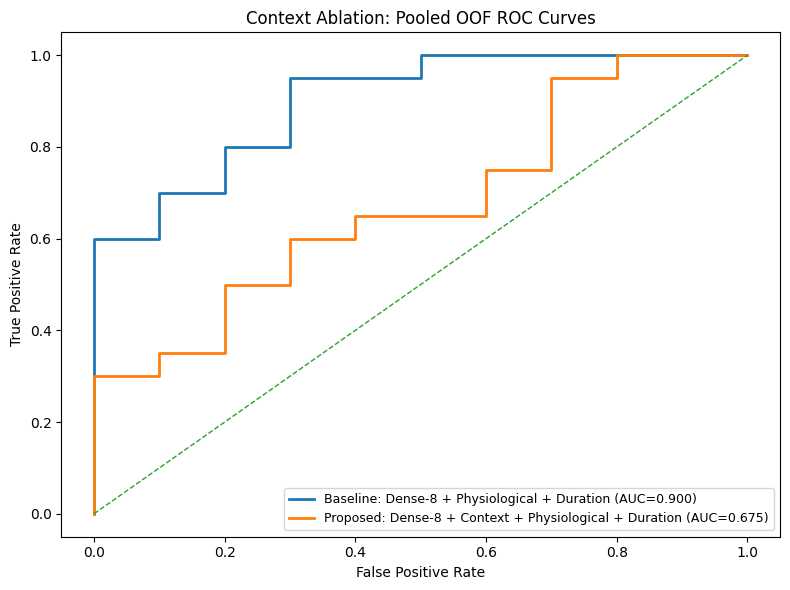

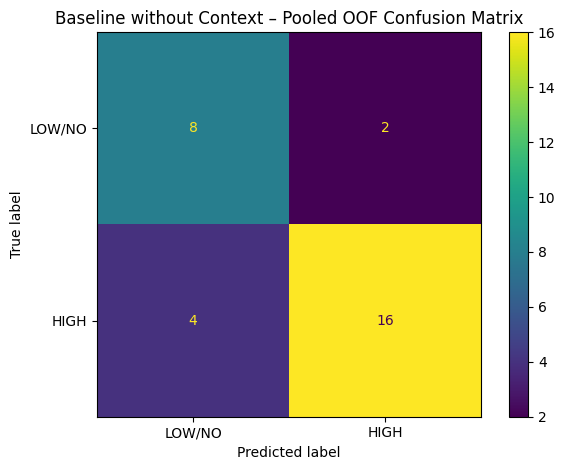

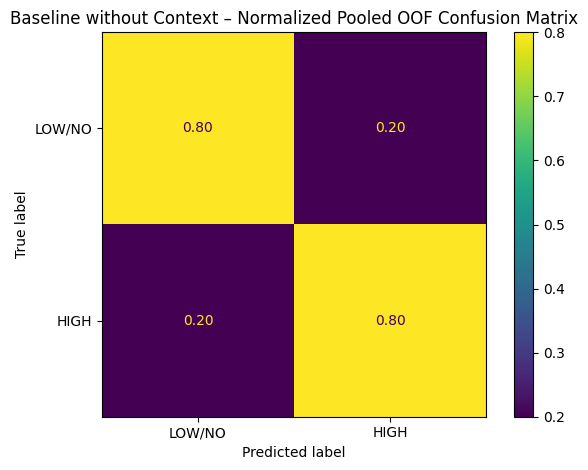

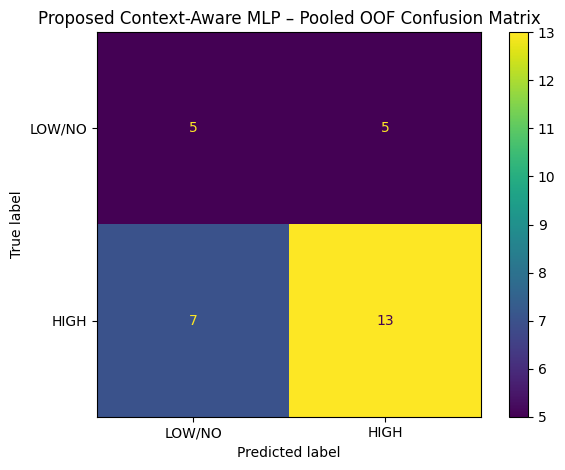

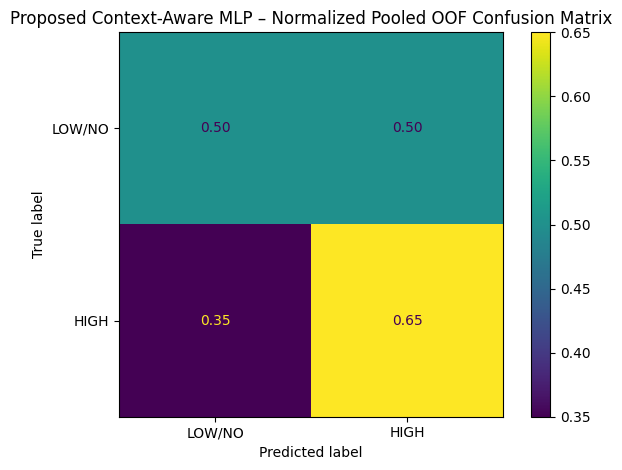

,model,projection_dim,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,MLP_Dense8_Duration_Physiological,8,0.900,0.950196,0.8,0.800,0.777778,0.800,0.784689,0.8,0.80,8,2,4,16
1,MLP_Dense8_Context_Duration_Physiological,8,0.675,0.833013,0.6,0.575,0.569444,0.575,0.569378,0.5,0.65,5,5,7,13


In [ ]:
# ============================================================
# STEP 12: POOLED OOF EVALUATION, ROC CURVES, AND CONFUSION MATRICES
# ============================================================

pooled_prediction_rows = []
pooled_metric_rows = []

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:
    model_predictions = ablation_predictions_df[
        ablation_predictions_df["model"] == model_name
    ]

    pooled_df = (
        model_predictions
        .groupby(["subject", "true_label"], as_index=False)
        .agg(
            probability_high=("probability_high", "mean"),
            probability_std=("probability_high", "std"),
        )
        .set_index("subject")
        .loc[subjects]
        .reset_index()
    )

    pooled_probabilities = pooled_df[
        "probability_high"
    ].to_numpy(dtype=float)

    pooled_metrics = calculate_binary_metrics(
        y,
        pooled_probabilities,
    )

    pooled_metric_rows.append({
        "model": model_name,
        "projection_dim": SELECTED_PROJECTION_DIM,
        **pooled_metrics,
    })

    pooled_df["model"] = model_name
    pooled_df["predicted_label"] = (
        pooled_probabilities >= THRESHOLD
    ).astype(int)
    pooled_prediction_rows.append(pooled_df)

pooled_predictions_df = pd.concat(
    pooled_prediction_rows,
    ignore_index=True,
)
pooled_metrics_df = pd.DataFrame(
    pooled_metric_rows
)

pooled_predictions_df.to_csv(
    COMPARISON_TABLE_DIR / "Pooled_OOF_Predictions.csv",
    index=False,
)
pooled_metrics_df.to_csv(
    COMPARISON_TABLE_DIR / "Pooled_OOF_Performance.csv",
    index=False,
)

plt.figure(figsize=(8, 6))

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:
    model_pooled = (
        pooled_predictions_df[
            pooled_predictions_df["model"] == model_name
        ]
        .set_index("subject")
        .loc[subjects]
    )

    probabilities = model_pooled[
        "probability_high"
    ].to_numpy()

    fpr, tpr, _ = roc_curve(y, probabilities)
    auc_value = roc_auc_score(y, probabilities)

    display_name = (
        "Baseline: Dense-8 + Physiological + Duration"
        if model_name == BASELINE_MODEL_NAME
        else "Proposed: Dense-8 + Context + Physiological + Duration"
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{display_name} (AUC={auc_value:.3f})",
    )

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Context Ablation: Pooled OOF ROC Curves")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(
    COMPARISON_FIGURE_DIR / "Context_Ablation_Pooled_OOF_ROC.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

for model_name, figure_dir in [
    (BASELINE_MODEL_NAME, BASELINE_FIGURE_DIR),
    (PROPOSED_MODEL_NAME, PROPOSED_FIGURE_DIR),
]:
    model_pooled = (
        pooled_predictions_df[
            pooled_predictions_df["model"] == model_name
        ]
        .set_index("subject")
        .loc[subjects]
    )

    probabilities = model_pooled[
        "probability_high"
    ].to_numpy()

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(y, predictions, labels=[0, 1])

    display_name = (
        "Baseline without Context"
        if model_name == BASELINE_MODEL_NAME
        else "Proposed Context-Aware MLP"
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["LOW/NO", "HIGH"],
    )
    display_cm.plot(values_format="d")
    plt.title(f"{display_name} – Pooled OOF Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        figure_dir / "Pooled_OOF_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    normalized_cm = confusion_matrix(
        y,
        predictions,
        labels=[0, 1],
        normalize="true",
    )

    normalized_display = ConfusionMatrixDisplay(
        confusion_matrix=normalized_cm,
        display_labels=["LOW/NO", "HIGH"],
    )
    normalized_display.plot(values_format=".2f")
    plt.title(
        f"{display_name} – Normalized Pooled OOF Confusion Matrix"
    )
    plt.tight_layout()
    plt.savefig(
        figure_dir / "Normalized_Pooled_OOF_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

display(pooled_metrics_df)

,test,seed,paired_quantity,statistic,p_value,significant_at_0.05,baseline_mean_error,context_aware_mean_error,context_minus_baseline_error,lower_error_model
0,Wilcoxon signed-rank test,42,Subject-level absolute probability error,130.0,0.0345,Yes,0.3622,0.4413,0.0790,Baseline
1,Wilcoxon signed-rank test,123,Subject-level absolute probability error,133.0,0.0405,Yes,0.3141,0.4063,0.0922,Baseline
2,Wilcoxon signed-rank test,2026,Subject-level absolute probability error,140.0,0.0577,No,0.4099,0.4580,0.0481,Baseline
3,McNemar exact test,Pooled,Subject-level prediction correctness,1.0,0.0703,No,NaN,NaN,NaN,Not applicable


MCNEMAR CONTINGENCY TABLE


,Context-Aware Incorrect,Context-Aware Correct
Baseline Incorrect,5,1
Baseline Correct,7,17


McNemar statistic: 1.0000
McNemar p-value  : 0.0703
Statistically significant: No


,seed,baseline_mean_error,baseline_std_error,context_aware_mean_error,context_aware_std_error,context_minus_baseline_error
0,42,0.3622,0.1771,0.4413,0.1654,0.0790
1,123,0.3141,0.2257,0.4063,0.2438,0.0922
2,2026,0.4099,0.1966,0.4580,0.1994,0.0481


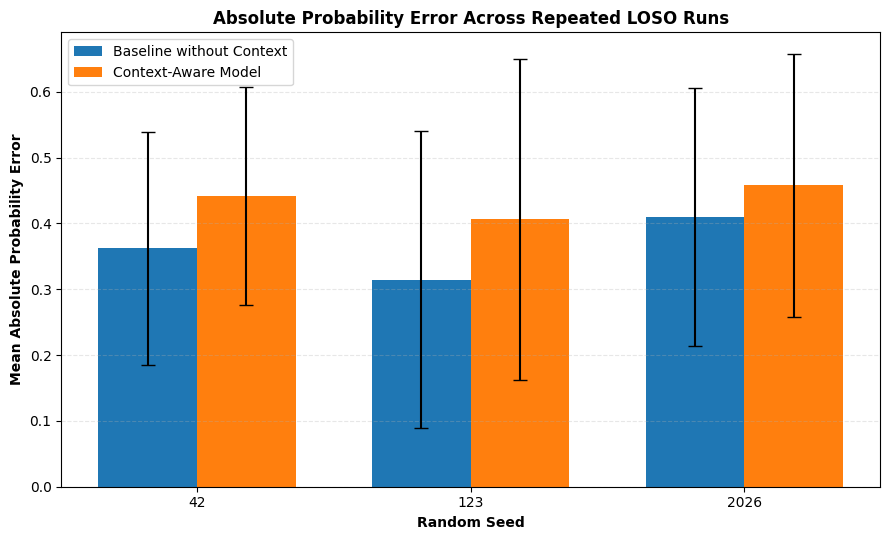

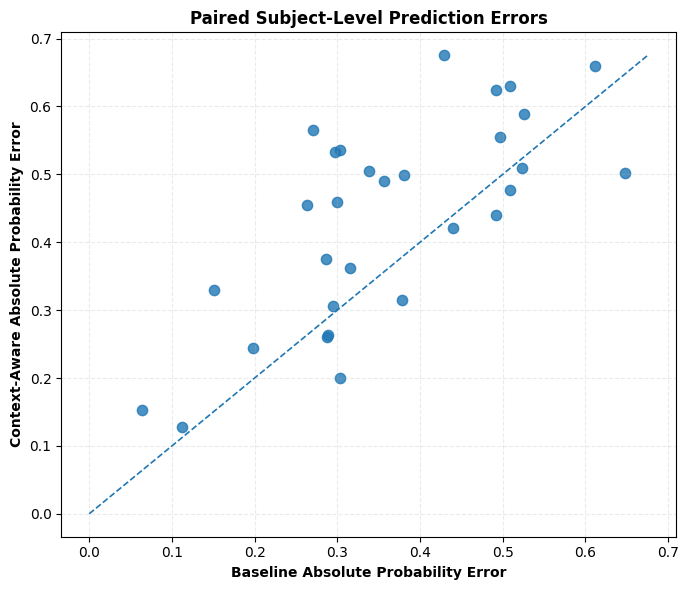

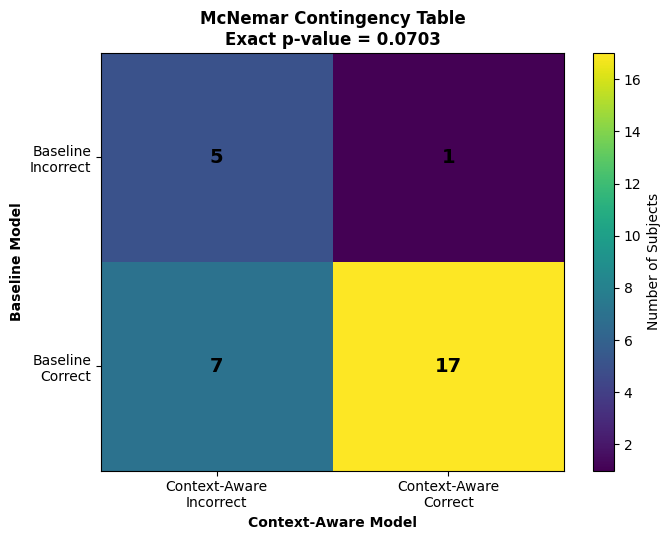

PAIRED STATISTICAL ANALYSIS COMPLETED
Statistical table: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/04_Context_Ablation_Comparison/Tables/Context_Ablation_Paired_Statistical_Tests.csv
Error summary table: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/04_Context_Ablation_Comparison/Tables/Mean_Absolute_Probability_Error_By_Seed.csv
McNemar table: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/04_Context_Ablation_Comparison/Tables/McNemar_Contingency_Table.csv
Figures directory: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/04_Context_Ablation_Comparison/Figures


In [ ]:
# ============================================================
# STEP 13: PAIRED STATISTICAL TESTS AND VISUALIZATION
#
# Statistical analyses:
# 1. Wilcoxon signed-rank test on paired subject-level
#    absolute probability errors for each random seed.
# 2. McNemar exact test on pooled subject-level correctness.
#
# Outputs:
# 1. Statistical-test summary table
# 2. McNemar contingency table
# 3. Mean absolute probability error comparison figure
# 4. McNemar contingency heatmap
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SIGNIFICANCE_LEVEL = 0.05

BASELINE_DISPLAY_NAME = (
    "Dense-8 + Physiological + Phase Duration"
)

PROPOSED_DISPLAY_NAME = (
    "Dense-8 + Context + Physiological + Phase Duration"
)


# ------------------------------------------------------------
# 2. WILCOXON SIGNED-RANK TEST
# ------------------------------------------------------------

paired_rows = []
error_comparison_rows = []

for seed in RANDOM_SEEDS:

    baseline_seed = (
        baseline_predictions_df[
            baseline_predictions_df["seed"] == seed
        ]
        .set_index("subject")
        .loc[subjects]
    )

    proposed_seed = (
        proposed_predictions_df[
            proposed_predictions_df["seed"] == seed
        ]
        .set_index("subject")
        .loc[subjects]
    )

    baseline_probability = (
        baseline_seed[
            "probability_high"
        ].to_numpy(dtype=float)
    )

    proposed_probability = (
        proposed_seed[
            "probability_high"
        ].to_numpy(dtype=float)
    )

    baseline_error = np.abs(
        y - baseline_probability
    )

    proposed_error = np.abs(
        y - proposed_probability
    )

    error_difference = (
        baseline_error
        - proposed_error
    )

    if np.allclose(
        error_difference,
        0,
    ):
        statistic = 0.0
        p_value = 1.0

    else:
        statistic, p_value = wilcoxon(
            baseline_error,
            proposed_error,
            alternative="two-sided",
            zero_method="wilcox",
        )

    baseline_mean_error = float(
        baseline_error.mean()
    )

    proposed_mean_error = float(
        proposed_error.mean()
    )

    mean_error_difference = float(
        proposed_mean_error
        - baseline_mean_error
    )

    better_model = (
        "Baseline"
        if baseline_mean_error < proposed_mean_error
        else "Context-Aware"
        if proposed_mean_error < baseline_mean_error
        else "Equal"
    )

    paired_rows.append({
        "test": "Wilcoxon signed-rank test",
        "seed": seed,
        "paired_quantity": (
            "Subject-level absolute probability error"
        ),
        "statistic": float(statistic),
        "p_value": float(p_value),
        "significant_at_0.05": (
            "Yes"
            if p_value < SIGNIFICANCE_LEVEL
            else "No"
        ),
        "baseline_mean_error": (
            baseline_mean_error
        ),
        "context_aware_mean_error": (
            proposed_mean_error
        ),
        "context_minus_baseline_error": (
            mean_error_difference
        ),
        "lower_error_model": better_model,
    })

    for subject_index, subject in enumerate(
        subjects
    ):
        error_comparison_rows.append({
            "seed": seed,
            "subject": subject,
            "true_label": int(
                y[subject_index]
            ),
            "baseline_error": float(
                baseline_error[
                    subject_index
                ]
            ),
            "context_aware_error": float(
                proposed_error[
                    subject_index
                ]
            ),
            "error_difference": float(
                proposed_error[
                    subject_index
                ]
                - baseline_error[
                    subject_index
                ]
            ),
        })


# ------------------------------------------------------------
# 3. MCNEMAR EXACT TEST
# ------------------------------------------------------------

baseline_pooled = (
    pooled_predictions_df[
        pooled_predictions_df["model"]
        == BASELINE_MODEL_NAME
    ]
    .set_index("subject")
    .loc[subjects]
)

proposed_pooled = (
    pooled_predictions_df[
        pooled_predictions_df["model"]
        == PROPOSED_MODEL_NAME
    ]
    .set_index("subject")
    .loc[subjects]
)

baseline_correct = (
    baseline_pooled[
        "predicted_label"
    ].to_numpy(dtype=int)
    == y
)

proposed_correct = (
    proposed_pooled[
        "predicted_label"
    ].to_numpy(dtype=int)
    == y
)

contingency_table = np.array([
    [
        np.sum(
            ~baseline_correct
            & ~proposed_correct
        ),
        np.sum(
            ~baseline_correct
            & proposed_correct
        ),
    ],
    [
        np.sum(
            baseline_correct
            & ~proposed_correct
        ),
        np.sum(
            baseline_correct
            & proposed_correct
        ),
    ],
])

mcnemar_result = mcnemar(
    contingency_table,
    exact=True,
)

paired_rows.append({
    "test": "McNemar exact test",
    "seed": "Pooled",
    "paired_quantity": (
        "Subject-level prediction correctness"
    ),
    "statistic": float(
        mcnemar_result.statistic
    ),
    "p_value": float(
        mcnemar_result.pvalue
    ),
    "significant_at_0.05": (
        "Yes"
        if mcnemar_result.pvalue
        < SIGNIFICANCE_LEVEL
        else "No"
    ),
    "baseline_mean_error": np.nan,
    "context_aware_mean_error": np.nan,
    "context_minus_baseline_error": np.nan,
    "lower_error_model": "Not applicable",
})


# ------------------------------------------------------------
# 4. CREATE STATISTICAL-SUMMARY TABLE
# ------------------------------------------------------------

statistical_comparison_df = pd.DataFrame(
    paired_rows
)

statistical_comparison_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Context_Ablation_Paired_Statistical_Tests.csv",
    index=False,
)

error_comparison_df = pd.DataFrame(
    error_comparison_rows
)

error_comparison_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Subject_Level_Absolute_Probability_Errors.csv",
    index=False,
)

display(
    statistical_comparison_df.round(4)
)


# ------------------------------------------------------------
# 5. CREATE AND SAVE MCNEMAR CONTINGENCY TABLE
# ------------------------------------------------------------

mcnemar_contingency_df = pd.DataFrame(
    contingency_table,
    index=[
        "Baseline Incorrect",
        "Baseline Correct",
    ],
    columns=[
        "Context-Aware Incorrect",
        "Context-Aware Correct",
    ],
)

mcnemar_contingency_df.to_csv(
    COMPARISON_TABLE_DIR
    / "McNemar_Contingency_Table.csv"
)

print("=" * 72)
print("MCNEMAR CONTINGENCY TABLE")
print("=" * 72)

display(
    mcnemar_contingency_df
)

print(
    "McNemar statistic:",
    f"{float(mcnemar_result.statistic):.4f}",
)

print(
    "McNemar p-value  :",
    f"{float(mcnemar_result.pvalue):.4f}",
)

print(
    "Statistically significant:",
    (
        "Yes"
        if mcnemar_result.pvalue
        < SIGNIFICANCE_LEVEL
        else "No"
    ),
)


# ------------------------------------------------------------
# 6. MEAN ABSOLUTE PROBABILITY ERROR TABLE
# ------------------------------------------------------------

error_summary_df = (
    error_comparison_df
    .groupby(
        "seed",
        as_index=False,
    )
    .agg(
        baseline_mean_error=(
            "baseline_error",
            "mean",
        ),
        baseline_std_error=(
            "baseline_error",
            "std",
        ),
        context_aware_mean_error=(
            "context_aware_error",
            "mean",
        ),
        context_aware_std_error=(
            "context_aware_error",
            "std",
        ),
    )
)

error_summary_df[
    "context_minus_baseline_error"
] = (
    error_summary_df[
        "context_aware_mean_error"
    ]
    - error_summary_df[
        "baseline_mean_error"
    ]
)

error_summary_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Mean_Absolute_Probability_Error_By_Seed.csv",
    index=False,
)

display(
    error_summary_df.round(4)
)


# ------------------------------------------------------------
# 7. FIGURE 1:
# MEAN ABSOLUTE PROBABILITY ERROR BY RANDOM SEED
# ------------------------------------------------------------

x_positions = np.arange(
    len(error_summary_df)
)

bar_width = 0.36

plt.figure(
    figsize=(9, 5.5)
)

plt.bar(
    x_positions - bar_width / 2,
    error_summary_df[
        "baseline_mean_error"
    ],
    width=bar_width,
    yerr=error_summary_df[
        "baseline_std_error"
    ],
    capsize=5,
    label="Baseline without Context",
)

plt.bar(
    x_positions + bar_width / 2,
    error_summary_df[
        "context_aware_mean_error"
    ],
    width=bar_width,
    yerr=error_summary_df[
        "context_aware_std_error"
    ],
    capsize=5,
    label="Context-Aware Model",
)

plt.xticks(
    x_positions,
    error_summary_df[
        "seed"
    ].astype(str),
)

plt.xlabel(
    "Random Seed",
    fontweight="bold",
)

plt.ylabel(
    "Mean Absolute Probability Error",
    fontweight="bold",
)

plt.title(
    "Absolute Probability Error Across Repeated LOSO Runs",
    fontweight="bold",
)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.30,
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "Mean_Absolute_Probability_Error_By_Seed.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 8. FIGURE 2:
# SUBJECT-LEVEL PAIRED ERROR COMPARISON
# ------------------------------------------------------------

mean_subject_errors = (
    error_comparison_df
    .groupby(
        "subject",
        as_index=False,
    )
    .agg(
        baseline_error=(
            "baseline_error",
            "mean",
        ),
        context_aware_error=(
            "context_aware_error",
            "mean",
        ),
    )
)

plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    mean_subject_errors[
        "baseline_error"
    ],
    mean_subject_errors[
        "context_aware_error"
    ],
    s=55,
    alpha=0.80,
)

maximum_error = max(
    mean_subject_errors[
        "baseline_error"
    ].max(),
    mean_subject_errors[
        "context_aware_error"
    ].max(),
)

plt.plot(
    [0, maximum_error],
    [0, maximum_error],
    linestyle="--",
    linewidth=1.2,
)

plt.xlabel(
    "Baseline Absolute Probability Error",
    fontweight="bold",
)

plt.ylabel(
    "Context-Aware Absolute Probability Error",
    fontweight="bold",
)

plt.title(
    "Paired Subject-Level Prediction Errors",
    fontweight="bold",
)

plt.grid(
    linestyle="--",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "Paired_Subject_Level_Probability_Errors.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 9. FIGURE 3:
# MCNEMAR CONTINGENCY HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

image = ax.imshow(
    contingency_table,
    aspect="auto",
)

ax.set_xticks(
    [0, 1]
)

ax.set_xticklabels(
    [
        "Context-Aware\nIncorrect",
        "Context-Aware\nCorrect",
    ]
)

ax.set_yticks(
    [0, 1]
)

ax.set_yticklabels(
    [
        "Baseline\nIncorrect",
        "Baseline\nCorrect",
    ]
)

for row_index in range(
    contingency_table.shape[0]
):
    for column_index in range(
        contingency_table.shape[1]
    ):
        ax.text(
            column_index,
            row_index,
            str(
                contingency_table[
                    row_index,
                    column_index,
                ]
            ),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
        )

ax.set_xlabel(
    "Context-Aware Model",
    fontweight="bold",
)

ax.set_ylabel(
    "Baseline Model",
    fontweight="bold",
)

ax.set_title(
    (
        "McNemar Contingency Table\n"
        f"Exact p-value = "
        f"{mcnemar_result.pvalue:.4f}"
    ),
    fontweight="bold",
)

fig.colorbar(
    image,
    ax=ax,
    label="Number of Subjects",
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "McNemar_Contingency_Heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 10. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("=" * 72)
print("PAIRED STATISTICAL ANALYSIS COMPLETED")
print("=" * 72)

print(
    "Statistical table:",
    COMPARISON_TABLE_DIR
    / "Context_Ablation_Paired_Statistical_Tests.csv",
)

print(
    "Error summary table:",
    COMPARISON_TABLE_DIR
    / "Mean_Absolute_Probability_Error_By_Seed.csv",
)

print(
    "McNemar table:",
    COMPARISON_TABLE_DIR
    / "McNemar_Contingency_Table.csv",
)

print(
    "Figures directory:",
    COMPARISON_FIGURE_DIR,
)

print("=" * 72)

In [ ]:
# ============================================================
# STEP 14: SELECT THE BEST FINAL MODEL CONFIGURATION
#
# Selection priority:
# 1. Mean ROC-AUC across repeated LOSO runs
# 2. Mean Macro F1
# 3. Mean Balanced Accuracy
#
# The selected model and its fold artifacts are passed
# automatically to the subsequent OOF SHAP analysis.
# ============================================================

baseline_fusion_dimension = (
    SELECTED_PROJECTION_DIM
    + len(PHYSIO_COLS)
    + len(DURATION_COLS)
)

proposed_fusion_dimension = (
    SELECTED_PROJECTION_DIM
    + len(CONTEXT_COLS)
    + len(PHYSIO_COLS)
    + len(DURATION_COLS)
)

model_ranking_df = (
    ablation_metrics_df
    .groupby(
        [
            "model",
            "include_context",
            "projection_dim",
        ],
        as_index=False,
    )
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        accuracy_mean=("accuracy", "mean"),
        balanced_accuracy_mean=(
            "balanced_accuracy",
            "mean",
        ),
        macro_precision_mean=(
            "macro_precision",
            "mean",
        ),
        macro_recall_mean=(
            "macro_recall",
            "mean",
        ),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        specificity_mean=(
            "specificity_low_no",
            "mean",
        ),
        sensitivity_mean=(
            "sensitivity_high",
            "mean",
        ),
    )
    .sort_values(
        by=[
            "roc_auc_mean",
            "macro_f1_mean",
            "balanced_accuracy_mean",
        ],
        ascending=[False, False, False],
    )
    .reset_index(drop=True)
)

model_ranking_df.insert(
    0,
    "rank",
    np.arange(1, len(model_ranking_df) + 1),
)

best_row = model_ranking_df.iloc[0]

BEST_MODEL_NAME = str(best_row["model"])
BEST_INCLUDE_CONTEXT = bool(best_row["include_context"])
BEST_PROJECTION_DIM = int(best_row["projection_dim"])

if BEST_INCLUDE_CONTEXT:
    BEST_CONFIGURATION_NAME = (
        "Dense-8 + Context + Physiological + Phase Duration"
    )
    BEST_FUSION_DIMENSION = proposed_fusion_dimension
    BEST_ARTIFACTS_DF = proposed_artifacts_df.copy()
    BEST_PREDICTIONS_DF = proposed_predictions_df.copy()
    BEST_TABLE_DIR = PROPOSED_TABLE_DIR
    BEST_FIGURE_DIR = PROPOSED_FIGURE_DIR
else:
    BEST_CONFIGURATION_NAME = (
        "Dense-8 + Physiological + Phase Duration"
    )
    BEST_FUSION_DIMENSION = baseline_fusion_dimension
    BEST_ARTIFACTS_DF = baseline_artifacts_df.copy()
    BEST_PREDICTIONS_DF = baseline_predictions_df.copy()
    BEST_TABLE_DIR = BASELINE_TABLE_DIR
    BEST_FIGURE_DIR = BASELINE_FIGURE_DIR

if len(BEST_ARTIFACTS_DF) != len(subjects):
    raise RuntimeError(
        "The selected model's primary-seed fold artifacts "
        "are incomplete."
    )

configuration_df = pd.DataFrame([
    {
        "configuration": (
            "Dense-8 + Physiological + Phase Duration"
        ),
        "model": BASELINE_MODEL_NAME,
        "include_context": False,
        "skeleton_projection": SELECTED_PROJECTION_DIM,
        "context_features": 0,
        "physiological_features": len(PHYSIO_COLS),
        "phase_duration_features": len(DURATION_COLS),
        "fusion_dimension": baseline_fusion_dimension,
    },
    {
        "configuration": (
            "Dense-8 + Context + Physiological "
            "+ Phase Duration"
        ),
        "model": PROPOSED_MODEL_NAME,
        "include_context": True,
        "skeleton_projection": SELECTED_PROJECTION_DIM,
        "context_features": len(CONTEXT_COLS),
        "physiological_features": len(PHYSIO_COLS),
        "phase_duration_features": len(DURATION_COLS),
        "fusion_dimension": proposed_fusion_dimension,
    },
])

configuration_df["selected_as_best_model"] = (
    configuration_df["model"] == BEST_MODEL_NAME
)

configuration_df = configuration_df.merge(
    model_ranking_df[
        [
            "rank",
            "model",
            "roc_auc_mean",
            "roc_auc_std",
            "pr_auc_mean",
            "accuracy_mean",
            "balanced_accuracy_mean",
            "macro_f1_mean",
            "macro_f1_std",
            "specificity_mean",
            "sensitivity_mean",
        ]
    ],
    on="model",
    how="left",
).sort_values("rank").reset_index(drop=True)

configuration_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Final_Experiment_Configurations.csv",
    index=False,
)

model_ranking_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Final_Model_Ranking.csv",
    index=False,
)

selected_model_summary = {
    "selected_model": BEST_MODEL_NAME,
    "selected_configuration": BEST_CONFIGURATION_NAME,
    "include_context": BEST_INCLUDE_CONTEXT,
    "selected_projection_dimension": BEST_PROJECTION_DIM,
    "fusion_dimension": BEST_FUSION_DIMENSION,
    "selection_priority": [
        "Mean ROC-AUC",
        "Mean Macro F1",
        "Mean Balanced Accuracy",
    ],
    "mean_roc_auc": float(best_row["roc_auc_mean"]),
    "mean_macro_f1": float(best_row["macro_f1_mean"]),
    "mean_balanced_accuracy": float(
        best_row["balanced_accuracy_mean"]
    ),
    "validation": "Repeated LOSO",
    "random_seeds": RANDOM_SEEDS,
    "oof_shap_target_model": BEST_MODEL_NAME,
}

with open(
    COMPARISON_DIR / "Selected_Best_Model.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        selected_model_summary,
        file,
        indent=2,
    )

print("=" * 78)
print("FINAL MODEL SELECTION")
print("=" * 78)
print("Selected model             :", BEST_MODEL_NAME)
print("Selected configuration     :", BEST_CONFIGURATION_NAME)
print("Include context            :", BEST_INCLUDE_CONTEXT)
print("Selected projection        :", BEST_PROJECTION_DIM)
print("Fusion dimension           :", BEST_FUSION_DIMENSION)
print(
    "Mean ROC-AUC               :",
    f"{float(best_row['roc_auc_mean']):.4f}",
)
print(
    "Mean Macro F1              :",
    f"{float(best_row['macro_f1_mean']):.4f}",
)
print(
    "Mean Balanced Accuracy     :",
    f"{float(best_row['balanced_accuracy_mean']):.4f}",
)
print("OOF SHAP target model      :", BEST_MODEL_NAME)
print("=" * 78)

display(configuration_df)
display(model_ranking_df)


FINAL MODEL SELECTION
Selected model             : MLP_Dense8_Duration_Physiological
Selected configuration     : Dense-8 + Physiological + Phase Duration
Include context            : False
Selected projection        : 8
Fusion dimension           : 18
Mean ROC-AUC               : 0.8467
Mean Macro F1              : 0.7573
Mean Balanced Accuracy     : 0.7667
OOF SHAP target model      : MLP_Dense8_Duration_Physiological


,configuration,model,include_context,skeleton_projection,context_features,physiological_features,phase_duration_features,fusion_dimension,selected_as_best_model,rank,roc_auc_mean,roc_auc_std,pr_auc_mean,accuracy_mean,balanced_accuracy_mean,macro_f1_mean,macro_f1_std,specificity_mean,sensitivity_mean
0,Dense-8 + Physiological + Phase Duration,MLP_Dense8_Duration_Physiological,False,8,0,5,5,18,True,1,0.846667,0.059652,0.917370,0.777778,0.766667,0.757274,0.016091,0.733333,0.800000
1,Dense-8 + Context + Physiological + Phase Dura...,MLP_Dense8_Context_Duration_Physiological,True,8,4,5,5,22,False,2,0.658333,0.059652,0.814856,0.644444,0.633333,0.620053,0.043594,0.600000,0.666667


,rank,model,include_context,projection_dim,roc_auc_mean,roc_auc_std,pr_auc_mean,accuracy_mean,balanced_accuracy_mean,macro_precision_mean,macro_recall_mean,macro_f1_mean,macro_f1_std,specificity_mean,sensitivity_mean
0,1,MLP_Dense8_Duration_Physiological,False,8,0.846667,0.059652,0.917370,0.777778,0.766667,0.754368,0.766667,0.757274,0.016091,0.733333,0.800000
1,2,MLP_Dense8_Context_Duration_Physiological,True,8,0.658333,0.059652,0.814856,0.644444,0.633333,0.624922,0.633333,0.620053,0.043594,0.600000,0.666667


# Cross-Validated OOF SHAP for the Automatically Selected Best Model

The following analysis explains the model selected in **STEP 14**.  
Each subject is explained using the primary-seed LOSO fold model that did not use that subject during training. Context features are included only when the selected configuration uses context.

In [ ]:
# ============================================================
# STEP 15: INSTALL SHAP AND PREPARE THE BEST FOLD ARTIFACTS
# ============================================================

!pip -q install shap

import shap

selected_artifacts_df = (
    BEST_ARTIFACTS_DF
    .sort_values("fold")
    .reset_index(drop=True)
)

if len(selected_artifacts_df) != len(subjects):
    raise RuntimeError(
        "The selected model's primary-seed fold artifacts "
        "are incomplete."
    )

PROJECTED_SKELETON_FEATURES = [
    f"projected_skeleton_{index + 1}"
    for index in range(BEST_PROJECTION_DIM)
]

if BEST_INCLUDE_CONTEXT:
    INTERNAL_FEATURE_NAMES = (
        PROJECTED_SKELETON_FEATURES
        + CONTEXT_COLS
        + PHYSIO_COLS
        + DURATION_COLS
    )
else:
    INTERNAL_FEATURE_NAMES = (
        PROJECTED_SKELETON_FEATURES
        + PHYSIO_COLS
        + DURATION_COLS
    )

INTERNAL_FEATURE_COUNT = len(
    INTERNAL_FEATURE_NAMES
)

feature_cursor = 0

FEATURE_GROUPS = {}

FEATURE_GROUPS["Projected Skeleton"] = (
    feature_cursor,
    feature_cursor + BEST_PROJECTION_DIM,
)
feature_cursor += BEST_PROJECTION_DIM

if BEST_INCLUDE_CONTEXT:
    FEATURE_GROUPS["Context"] = (
        feature_cursor,
        feature_cursor + len(CONTEXT_COLS),
    )
    feature_cursor += len(CONTEXT_COLS)

FEATURE_GROUPS["Physiological"] = (
    feature_cursor,
    feature_cursor + len(PHYSIO_COLS),
)
feature_cursor += len(PHYSIO_COLS)

FEATURE_GROUPS["Phase Duration"] = (
    feature_cursor,
    feature_cursor + len(DURATION_COLS),
)
feature_cursor += len(DURATION_COLS)

assert feature_cursor == INTERNAL_FEATURE_COUNT
assert len(INTERNAL_FEATURE_NAMES) == INTERNAL_FEATURE_COUNT

print("=" * 72)
print("OOF SHAP CONFIGURATION")
print("=" * 72)
print("SHAP target model        :", BEST_MODEL_NAME)
print("Selected configuration  :", BEST_CONFIGURATION_NAME)
print("Selected projection     :", BEST_PROJECTION_DIM)
print("Context included        :", BEST_INCLUDE_CONTEXT)
print("Internal SHAP features  :", INTERNAL_FEATURE_COUNT)
print("Feature groups          :", list(FEATURE_GROUPS.keys()))
print("=" * 72)


OOF SHAP CONFIGURATION
SHAP target model        : MLP_Dense8_Duration_Physiological
Selected configuration  : Dense-8 + Physiological + Phase Duration
Selected projection     : 8
Context included        : False
Internal SHAP features  : 18
Feature groups          : ['Projected Skeleton', 'Physiological', 'Phase Duration']


In [ ]:
# ============================================================
# STEP 16: DYNAMIC OOF SHAP HELPER FUNCTIONS
# ============================================================

def restore_scaler(mean_values, scale_values):
    scaler = StandardScaler()

    scaler.mean_ = np.asarray(
        mean_values,
        dtype=np.float64,
    )
    scaler.scale_ = np.asarray(
        scale_values,
        dtype=np.float64,
    )
    scaler.var_ = scaler.scale_ ** 2
    scaler.n_features_in_ = len(scaler.mean_)
    scaler.n_samples_seen_ = 1

    return scaler


def create_projection_extractor(
    trained_model,
    projection_dim,
):
    return tf.keras.Model(
        inputs=trained_model.inputs,
        outputs=trained_model.get_layer(
            f"skeleton_projection_bn_{projection_dim}"
        ).output,
        name=f"projection_extractor_{projection_dim}",
    )


def create_internal_fusion_head(
    trained_model,
    internal_feature_count,
):
    internal_input = tf.keras.layers.Input(
        shape=(internal_feature_count,),
        name="selected_internal_input",
    )

    x = trained_model.get_layer(
        "mlp_dense_64"
    )(internal_input)
    x = trained_model.get_layer(
        "mlp_batch_normalization_64"
    )(x)
    x = trained_model.get_layer(
        "mlp_dropout_64"
    )(x, training=False)

    x = trained_model.get_layer(
        "mlp_dense_32"
    )(x)
    x = trained_model.get_layer(
        "mlp_batch_normalization_32"
    )(x)
    x = trained_model.get_layer(
        "mlp_dropout_32"
    )(x, training=False)

    x = trained_model.get_layer(
        "mlp_dense_16"
    )(x)
    x = trained_model.get_layer(
        "mlp_dropout_16"
    )(x, training=False)

    output = trained_model.get_layer(
        "fall_risk_probability"
    )(x)

    return tf.keras.Model(
        inputs=internal_input,
        outputs=output,
        name="selected_internal_fusion_head",
    )


def build_internal_representation(
    projection_extractor,
    skeleton_scaled,
    physio_scaled,
    duration_scaled,
    context_scaled=None,
):
    model_inputs = pack_model_inputs(
        skeleton_scaled,
        context_scaled,
        physio_scaled,
        duration_scaled,
        include_context=BEST_INCLUDE_CONTEXT,
    )

    projected = projection_extractor.predict(
        model_inputs,
        verbose=0,
    ).astype(np.float32)

    internal_parts = [projected]

    if BEST_INCLUDE_CONTEXT:
        if context_scaled is None:
            raise ValueError(
                "Context input is required for the selected model."
            )
        internal_parts.append(context_scaled)

    internal_parts.extend([
        physio_scaled,
        duration_scaled,
    ])

    internal = np.concatenate(
        internal_parts,
        axis=1,
    ).astype(np.float32)

    if internal.shape[1] != INTERNAL_FEATURE_COUNT:
        raise ValueError(
            "Unexpected internal feature count: "
            f"{internal.shape[1]}; "
            f"expected {INTERNAL_FEATURE_COUNT}."
        )

    return internal


In [ ]:
# ============================================================
# STEP 17: COMPUTE CROSS-VALIDATED OOF SHAP
#
# Every subject is explained using the selected fold model
# that did not train on that subject.
# ============================================================

oof_internal_shap_values = np.zeros(
    (len(subjects), INTERNAL_FEATURE_COUNT),
    dtype=np.float32,
)
oof_internal_inputs = np.zeros(
    (len(subjects), INTERNAL_FEATURE_COUNT),
    dtype=np.float32,
)
oof_internal_base_values = np.zeros(
    len(subjects),
    dtype=np.float32,
)
oof_internal_probabilities = np.zeros(
    len(subjects),
    dtype=np.float32,
)

for artifact in selected_artifacts_df.itertuples(index=False):
    fold = int(artifact.fold)

    outer_train_idx = np.asarray(
        artifact.outer_train_idx,
        dtype=int,
    )
    test_idx = np.asarray(
        artifact.test_idx,
        dtype=int,
    )

    skeleton_scaler = restore_scaler(
        artifact.skeleton_mean,
        artifact.skeleton_scale,
    )
    physio_scaler = restore_scaler(
        artifact.physio_mean,
        artifact.physio_scale,
    )
    duration_scaler = restore_scaler(
        artifact.duration_mean,
        artifact.duration_scale,
    )

    if BEST_INCLUDE_CONTEXT:
        context_scaler = restore_scaler(
            artifact.context_mean,
            artifact.context_scale,
        )
    else:
        context_scaler = None

    model = build_multimodal_mlp_model(
        projection_dim=BEST_PROJECTION_DIM,
        include_context=BEST_INCLUDE_CONTEXT,
    )
    model.load_weights(artifact.weight_path)

    Xs_background = skeleton_scaler.transform(
        X_skeleton[outer_train_idx]
    ).astype(np.float32)
    Xp_background = physio_scaler.transform(
        X_physio[outer_train_idx]
    ).astype(np.float32)
    Xd_background = duration_scaler.transform(
        X_duration[outer_train_idx]
    ).astype(np.float32)

    Xs_test = skeleton_scaler.transform(
        X_skeleton[test_idx]
    ).astype(np.float32)
    Xp_test = physio_scaler.transform(
        X_physio[test_idx]
    ).astype(np.float32)
    Xd_test = duration_scaler.transform(
        X_duration[test_idx]
    ).astype(np.float32)

    if BEST_INCLUDE_CONTEXT:
        Xc_background = context_scaler.transform(
            X_context[outer_train_idx]
        ).astype(np.float32)
        Xc_test = context_scaler.transform(
            X_context[test_idx]
        ).astype(np.float32)
    else:
        Xc_background = None
        Xc_test = None

    projection_extractor = create_projection_extractor(
        model,
        BEST_PROJECTION_DIM,
    )
    internal_head = create_internal_fusion_head(
        model,
        INTERNAL_FEATURE_COUNT,
    )

    X_internal_background = build_internal_representation(
        projection_extractor=projection_extractor,
        skeleton_scaled=Xs_background,
        context_scaled=Xc_background,
        physio_scaled=Xp_background,
        duration_scaled=Xd_background,
    )
    X_internal_test = build_internal_representation(
        projection_extractor=projection_extractor,
        skeleton_scaled=Xs_test,
        context_scaled=Xc_test,
        physio_scaled=Xp_test,
        duration_scaled=Xd_test,
    )

    if len(X_internal_background) > SHAP_BACKGROUND_SIZE:
        background_rng = np.random.default_rng(
            PRIMARY_SEED + fold
        )
        selected_background_idx = background_rng.choice(
            len(X_internal_background),
            size=SHAP_BACKGROUND_SIZE,
            replace=False,
        )
        X_internal_background = X_internal_background[
            selected_background_idx
        ]

    def predict_internal(values):
        values = np.asarray(
            values,
            dtype=np.float32,
        )
        return internal_head.predict(
            values,
            verbose=0,
        ).ravel()

    explainer = shap.KernelExplainer(
        predict_internal,
        X_internal_background,
    )

    fold_shap_values = explainer.shap_values(
        X_internal_test,
        nsamples=SHAP_NSAMPLES,
        silent=True,
    )

    if isinstance(fold_shap_values, list):
        fold_shap_values = fold_shap_values[-1]

    fold_shap_values = np.asarray(
        fold_shap_values,
        dtype=np.float32,
    ).reshape(
        1,
        INTERNAL_FEATURE_COUNT,
    )

    test_position = int(test_idx[0])

    oof_internal_shap_values[
        test_position
    ] = fold_shap_values[0]
    oof_internal_inputs[
        test_position
    ] = X_internal_test[0]
    oof_internal_base_values[
        test_position
    ] = float(
        np.asarray(
            explainer.expected_value
        ).reshape(-1)[-1]
    )
    oof_internal_probabilities[
        test_position
    ] = float(
        predict_internal(X_internal_test)[0]
    )

    print(
        f"SHAP fold {fold:02d}/{len(subjects)} completed "
        f"| {subjects[test_position]}"
    )

    del model
    del projection_extractor
    del internal_head
    del explainer

    tf.keras.backend.clear_session()
    gc.collect()

if np.isnan(oof_internal_shap_values).any():
    raise RuntimeError(
        "OOF SHAP values contain missing values."
    )

selected_primary_probabilities = (
    BEST_PREDICTIONS_DF[
        BEST_PREDICTIONS_DF["seed"] == PRIMARY_SEED
    ]
    .set_index("subject")
    .loc[subjects]["probability_high"]
    .to_numpy(dtype=np.float32)
)

max_probability_difference = float(
    np.max(
        np.abs(
            oof_internal_probabilities
            - selected_primary_probabilities
        )
    )
)

print("=" * 72)
print("CROSS-VALIDATED OOF SHAP COMPLETED")
print("=" * 72)
print("Selected model             :", BEST_MODEL_NAME)
print("Context included           :", BEST_INCLUDE_CONTEXT)
print("SHAP matrix shape          :", oof_internal_shap_values.shape)
print(
    "Max restored probability difference:",
    max_probability_difference,
)
print("=" * 72)


SHAP fold 01/30 completed | subject01
SHAP fold 02/30 completed | subject02
SHAP fold 03/30 completed | subject03
SHAP fold 04/30 completed | subject04
SHAP fold 05/30 completed | subject05
SHAP fold 06/30 completed | subject06
SHAP fold 07/30 completed | subject07
SHAP fold 08/30 completed | subject08
SHAP fold 09/30 completed | subject09
SHAP fold 10/30 completed | subject10
SHAP fold 11/30 completed | subject11
SHAP fold 12/30 completed | subject12
SHAP fold 13/30 completed | subject13
SHAP fold 14/30 completed | subject14
SHAP fold 15/30 completed | subject15
SHAP fold 16/30 completed | subject16
SHAP fold 17/30 completed | subject17
SHAP fold 18/30 completed | subject18
SHAP fold 19/30 completed | subject19
SHAP fold 20/30 completed | subject20
SHAP fold 21/30 completed | subject21
SHAP fold 22/30 completed | subject22
SHAP fold 23/30 completed | subject23
SHAP fold 24/30 completed | subject24
SHAP fold 25/30 completed | subject25
SHAP fold 26/30 completed | subject26
SHAP fold 27

In [ ]:
# ============================================================
# STEP 18: GLOBAL AND FEATURE-GROUP SHAP ANALYSIS
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        oof_internal_shap_values
    ),
    axis=0,
)

global_shap_df = pd.DataFrame({
    "feature": INTERNAL_FEATURE_NAMES,
    "mean_abs_shap": mean_abs_shap,
})

def feature_group_name(
    feature_index,
):
    for group_name, (
        start,
        end,
    ) in FEATURE_GROUPS.items():
        if (
            start
            <= feature_index
            < end
        ):
            return group_name

    raise ValueError(
        feature_index
    )

global_shap_df[
    "feature_group"
] = [
    feature_group_name(index)
    for index in range(
        INTERNAL_FEATURE_COUNT
    )
]

global_shap_df = (
    global_shap_df
    .sort_values(
        "mean_abs_shap",
        ascending=False,
    )
    .reset_index(drop=True)
)

global_shap_df.insert(
    0,
    "rank",
    np.arange(
        1,
        len(global_shap_df) + 1,
    ),
)

global_shap_df.to_csv(
    SHAP_DIR
    / "Global_OOF_SHAP_Importance.csv",
    index=False,
)

group_rows = []

total_abs_shap = np.abs(
    oof_internal_shap_values
).sum()

for group_name, (
    start,
    end,
) in FEATURE_GROUPS.items():
    group_values = np.abs(
        oof_internal_shap_values[
            :,
            start:end,
        ]
    )

    group_rows.append({
        "feature_group": group_name,
        "feature_count": end - start,
        "total_abs_shap": float(
            group_values.sum()
        ),
        "mean_abs_shap_per_feature": float(
            group_values.mean()
        ),
        "contribution_percent": float(
            group_values.sum()
            / total_abs_shap
            * 100
        ),
    })

group_shap_df = (
    pd.DataFrame(group_rows)
    .sort_values(
        "contribution_percent",
        ascending=False,
    )
    .reset_index(drop=True)
)

group_shap_df.to_csv(
    SHAP_DIR
    / "OOF_SHAP_Feature_Group_Contribution.csv",
    index=False,
)

display(global_shap_df)
display(group_shap_df)

,rank,feature,mean_abs_shap,feature_group
0,1,duration_STTS,0.064809,Phase Duration
1,2,duration_WI,0.041125,Phase Duration
2,3,duration_WO,0.032688,Phase Duration
3,4,duration_TR,0.029789,Phase Duration
4,5,duration_STS,0.026388,Phase Duration
5,6,projected_skeleton_1,0.023218,Projected Skeleton
6,7,projected_skeleton_5,0.023217,Projected Skeleton
7,8,projected_skeleton_8,0.021454,Projected Skeleton
8,9,mean_spo2,0.015959,Physiological
9,10,bmi,0.014914,Physiological


,feature_group,feature_count,total_abs_shap,mean_abs_shap_per_feature,contribution_percent
0,Phase Duration,5,5.844001,0.038960,50.680424
1,Projected Skeleton,8,3.653434,0.015223,31.683353
2,Physiological,5,2.033647,0.013558,17.636219


OOF SHAP DATA
Number of subjects : 30
Number of features : 18
Output directory   : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global


,rank,feature,mean_absolute_shap
0,1,duration_STTS,0.064809
1,2,duration_WI,0.041125
2,3,duration_WO,0.032688
3,4,duration_TR,0.029789
4,5,duration_STS,0.026388
5,6,projected_skeleton_1,0.023218
6,7,projected_skeleton_5,0.023217
7,8,projected_skeleton_8,0.021454
8,9,mean_spo2,0.015959
9,10,bmi,0.014914


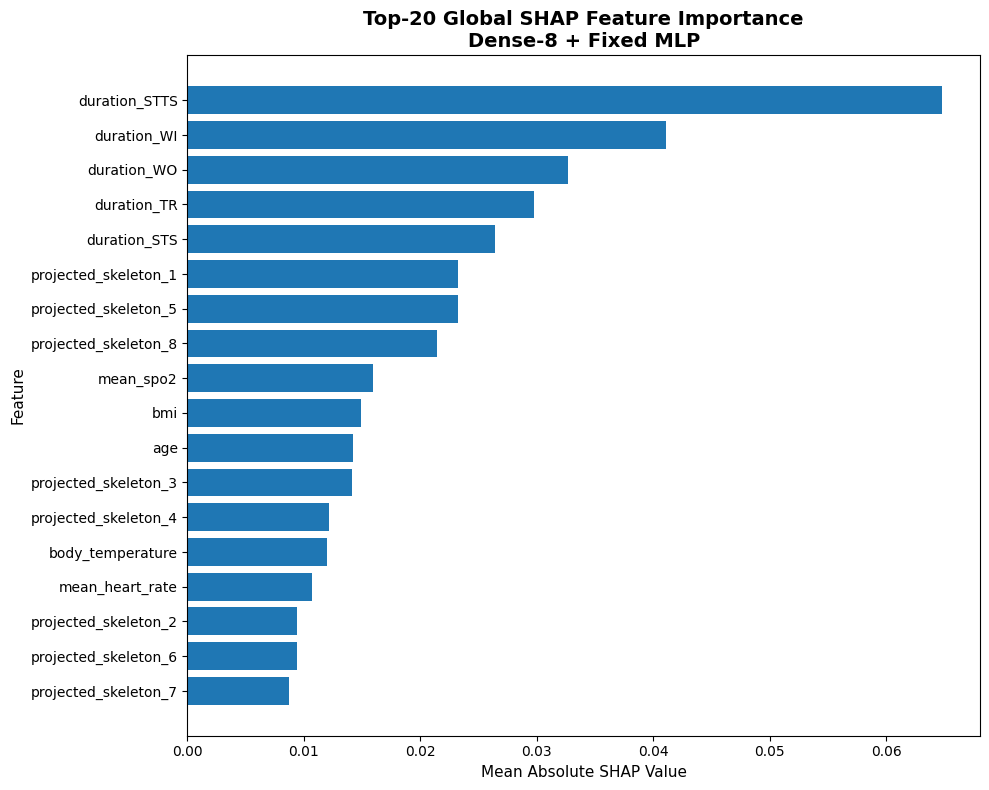

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Top_20_Global_SHAP_Feature_Importance.png


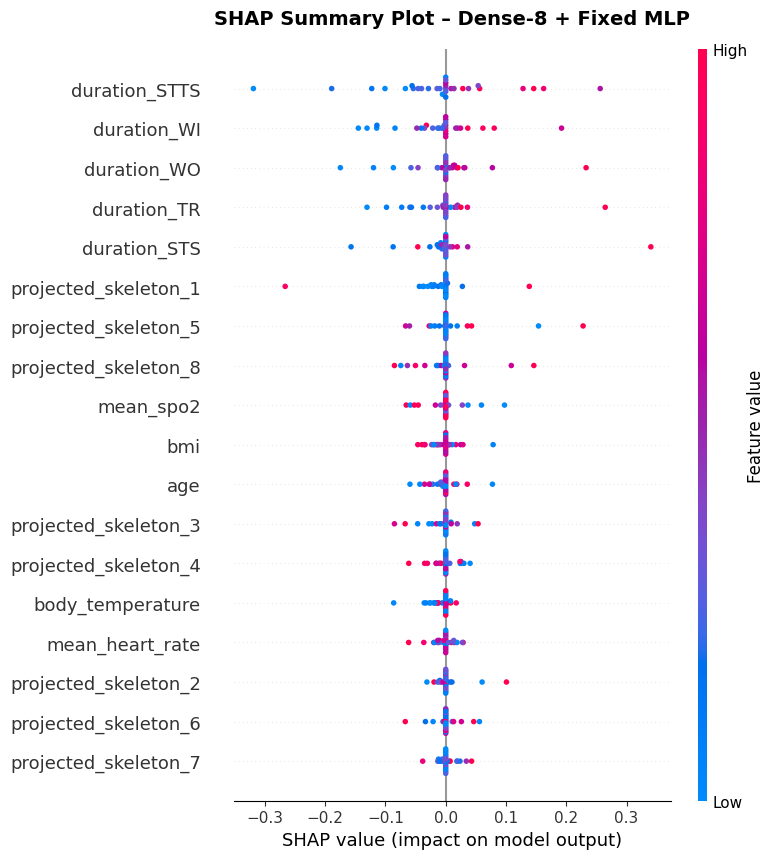

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/SHAP_Summary_Beeswarm_Dense_8.png


,feature_group,number_of_features,total_absolute_shap,mean_absolute_shap_per_feature,contribution_percent
0,Skeleton Embedding,8,0.121781,0.015223,31.683355
1,Phase Duration,5,0.194800,0.038960,50.680427
2,Physiological,5,0.067788,0.013558,17.636218


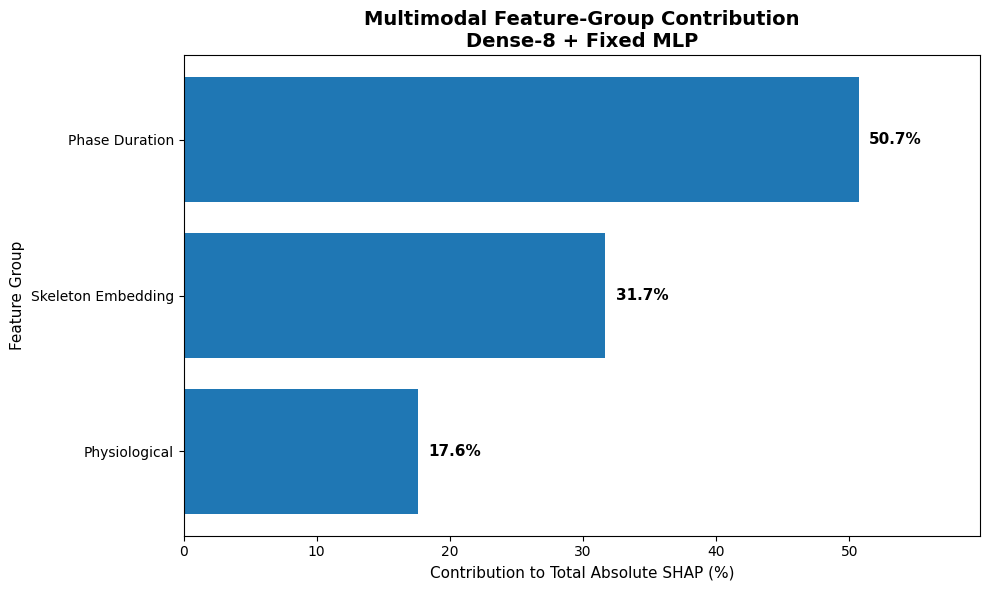

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Multimodal_Feature_Group_Contribution.png


<Figure size 700x500 with 0 Axes>

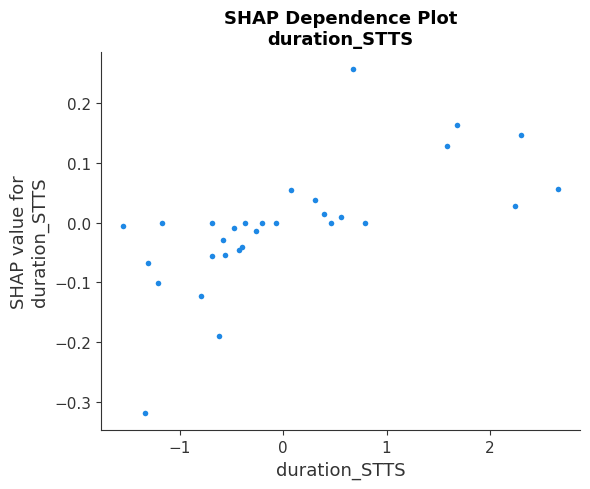

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_STTS_Dependence.png


<Figure size 700x500 with 0 Axes>

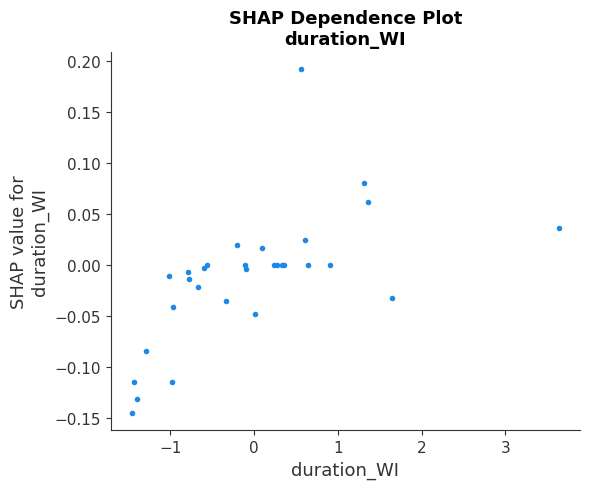

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_WI_Dependence.png


<Figure size 700x500 with 0 Axes>

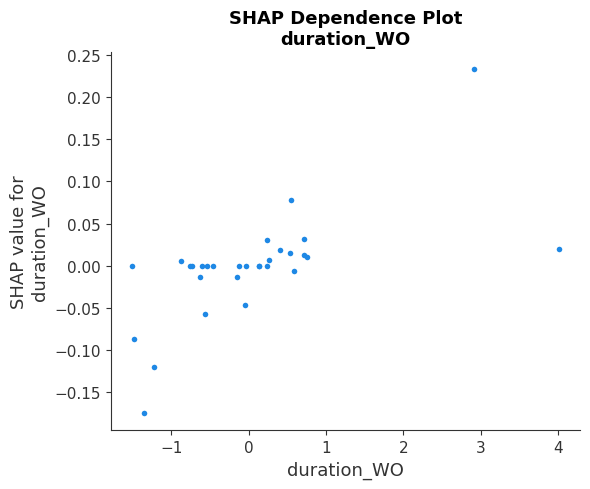

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_WO_Dependence.png


<Figure size 700x500 with 0 Axes>

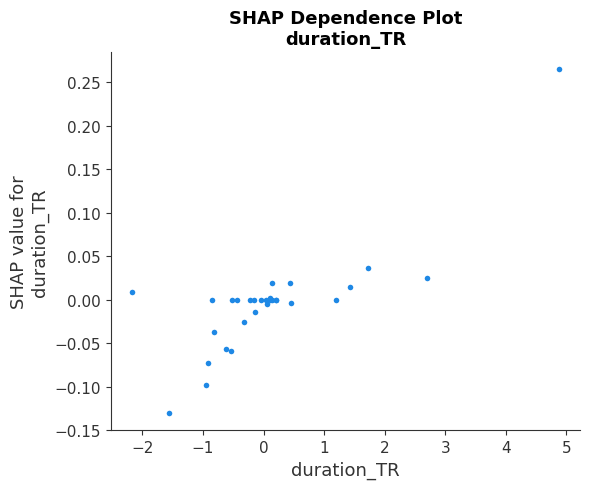

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_TR_Dependence.png


<Figure size 700x500 with 0 Axes>

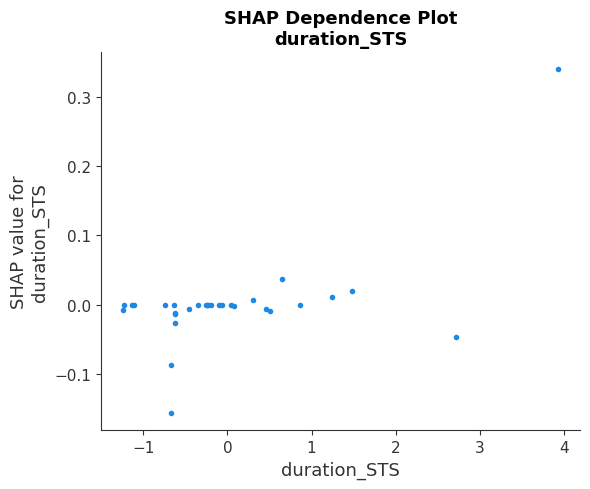

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_STS_Dependence.png
STEP 20 COMPLETED
Global feature importance: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Top_20_Global_SHAP_Feature_Importance.png
SHAP summary / beeswarm  : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/SHAP_Summary_Beeswarm_Dense_8.png
Feature-group contribution: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Multimodal_Feature_Group_Contribution.png
Dependence plot directory : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence


In [ ]:
# ============================================================
# STEP 19: GLOBAL SHAP ANALYSIS
#
# Outputs:
# 1. Top-20 Global SHAP Feature Importance
# 2. SHAP Summary / Beeswarm Plot
# 3. Multimodal Feature-Group Contribution
# 4. Feature-Group Contribution Table
# 5. SHAP Dependence Plots for Top Features
#
# Source:
# Out-of-Fold (OOF) SHAP values from LOSO evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from pathlib import Path


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TOP_N_FEATURES = 20
TOP_N_DEPENDENCE = 5
FIGURE_DPI = 300


# ------------------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "SHAP_DIR",
    "oof_internal_shap_values",
    "oof_internal_inputs",
    "INTERNAL_FEATURE_NAMES",
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "Variabel berikut belum tersedia:\n- "
        + "\n- ".join(missing_variables)
        + "\n\nJalankan cell perhitungan OOF SHAP terlebih dahulu."
    )


# ------------------------------------------------------------
# 3. OUTPUT DIRECTORIES
# ------------------------------------------------------------

SHAP_DIR = Path(SHAP_DIR)

GLOBAL_SHAP_DIR = (
    SHAP_DIR
    / "Global"
)

DEPENDENCE_DIR = (
    SHAP_DIR
    / "Dependence"
)

GLOBAL_SHAP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DEPENDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 4. PREPARE SHAP ARRAYS
# ------------------------------------------------------------

shap_values = np.asarray(
    oof_internal_shap_values,
    dtype=float,
)

shap_inputs = np.asarray(
    oof_internal_inputs,
    dtype=float,
)

feature_names = list(
    INTERNAL_FEATURE_NAMES
)


# Handle SHAP output shape:
# (samples, features, 1) → (samples, features)
if shap_values.ndim == 3:

    if shap_values.shape[-1] == 1:
        shap_values = shap_values[:, :, 0]

    elif shap_values.shape[0] == 1:
        shap_values = shap_values[0]

    else:
        raise ValueError(
            "Format SHAP values tidak dikenali: "
            f"{shap_values.shape}"
        )


# ------------------------------------------------------------
# 5. VALIDATE DIMENSIONS
# ------------------------------------------------------------

if shap_values.ndim != 2:
    raise ValueError(
        "SHAP values harus berbentuk dua dimensi.\n"
        f"Current shape: {shap_values.shape}"
    )

if shap_inputs.ndim != 2:
    raise ValueError(
        "OOF internal inputs harus berbentuk dua dimensi.\n"
        f"Current shape: {shap_inputs.shape}"
    )

if shap_values.shape != shap_inputs.shape:
    raise ValueError(
        "Dimensi SHAP values dan input tidak sama.\n"
        f"SHAP values : {shap_values.shape}\n"
        f"Input       : {shap_inputs.shape}"
    )

if shap_values.shape[1] != len(feature_names):
    raise ValueError(
        "Jumlah nama fitur tidak sama dengan jumlah fitur SHAP.\n"
        f"Feature names : {len(feature_names)}\n"
        f"SHAP features : {shap_values.shape[1]}"
    )

print("=" * 72)
print("OOF SHAP DATA")
print("=" * 72)
print("Number of subjects :", shap_values.shape[0])
print("Number of features :", shap_values.shape[1])
print("Output directory   :", GLOBAL_SHAP_DIR)
print("=" * 72)


# ------------------------------------------------------------
# 6. GLOBAL FEATURE IMPORTANCE
#
# Mean absolute SHAP for each feature
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0,
)

global_shap_df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": mean_abs_shap,
})

global_shap_df = (
    global_shap_df
    .sort_values(
        "mean_absolute_shap",
        ascending=False,
    )
    .reset_index(drop=True)
)

global_shap_df.insert(
    0,
    "rank",
    np.arange(
        1,
        len(global_shap_df) + 1,
    ),
)

global_shap_df.to_csv(
    GLOBAL_SHAP_DIR
    / "Global_SHAP_Feature_Importance.csv",
    index=False,
)

display(
    global_shap_df.head(
        TOP_N_FEATURES
    )
)


# ------------------------------------------------------------
# 7. TOP-20 GLOBAL FEATURE IMPORTANCE PLOT
# ------------------------------------------------------------

top_global_df = (
    global_shap_df
    .head(TOP_N_FEATURES)
    .sort_values(
        "mean_absolute_shap",
        ascending=True,
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_global_df["feature"],
    top_global_df["mean_absolute_shap"],
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=11,
)

plt.ylabel(
    "Feature",
    fontsize=11,
)

plt.title(
    f"Top-{TOP_N_FEATURES} Global SHAP Feature Importance\n"
    "Dense-8 + Fixed MLP",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()

global_importance_path = (
    GLOBAL_SHAP_DIR
    / "Top_20_Global_SHAP_Feature_Importance.png"
)

plt.savefig(
    global_importance_path,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved:",
    global_importance_path,
)


# ------------------------------------------------------------
# 8. SHAP SUMMARY / BEESWARM PLOT
# ------------------------------------------------------------

plt.figure()

shap.summary_plot(
    shap_values,
    shap_inputs,
    feature_names=feature_names,
    max_display=TOP_N_FEATURES,
    plot_type="dot",
    show=False,
)

plt.title(
    "SHAP Summary Plot – Dense-8 + Fixed MLP",
    fontsize=14,
    fontweight="bold",
    pad=18,
)

plt.tight_layout()

summary_plot_path = (
    GLOBAL_SHAP_DIR
    / "SHAP_Summary_Beeswarm_Dense_8.png"
)

plt.savefig(
    summary_plot_path,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved:",
    summary_plot_path,
)


# ------------------------------------------------------------
# 9. DEFINE FEATURE GROUPS
#
# Supported feature-name patterns:
# - Skeleton projection/internal features
# - Context
# - Physiological
# - Phase duration
# ------------------------------------------------------------

CONTEXT_FEATURES = {
    "temperature",
    "humidity",
    "light_intensity",
    "pressure",
}

PHYSIOLOGICAL_FEATURES = {
    "age",
    "bmi",
    "body_temperature",
    "mean_heart_rate",
    "heart_rate",
    "mean_spo2",
    "spo2",
}

DURATION_FEATURES = {
    "duration_STS",
    "duration_WO",
    "duration_TR",
    "duration_WI",
    "duration_STTS",
}


def classify_feature_group(
    feature_name,
):
    """
    Assign each feature to one multimodal feature group.
    """

    feature_name = str(
        feature_name
    )

    feature_lower = (
        feature_name.lower()
    )

    # Skeleton features may use names such as:
    # skel_emb_035
    # skeleton_projection_0
    # projected_skeleton_0
    # skeleton_0
    if (
        feature_lower.startswith("skel_")
        or feature_lower.startswith("skeleton_")
        or feature_lower.startswith("projected_")
        or "skeleton" in feature_lower
    ):
        return "Skeleton Embedding"

    if feature_name in CONTEXT_FEATURES:
        return "Context"

    if feature_name in PHYSIOLOGICAL_FEATURES:
        return "Physiological"

    if feature_name in DURATION_FEATURES:
        return "Phase Duration"

    # Additional robust matching
    if feature_lower.startswith("duration_"):
        return "Phase Duration"

    if feature_lower in {
        name.lower()
        for name in CONTEXT_FEATURES
    }:
        return "Context"

    if feature_lower in {
        name.lower()
        for name in PHYSIOLOGICAL_FEATURES
    }:
        return "Physiological"

    return "Unclassified"


feature_group_labels = [
    classify_feature_group(
        feature_name
    )
    for feature_name in feature_names
]


# ------------------------------------------------------------
# 10. CHECK UNCLASSIFIED FEATURES
# ------------------------------------------------------------

unclassified_features = [
    feature_name
    for feature_name, group_name
    in zip(
        feature_names,
        feature_group_labels,
    )
    if group_name == "Unclassified"
]

if unclassified_features:
    print(
        "WARNING: Fitur berikut belum dapat "
        "dikelompokkan secara otomatis:"
    )

    for feature_name in unclassified_features:
        print(
            "-",
            feature_name,
        )


# ------------------------------------------------------------
# 11. FEATURE-GROUP CONTRIBUTION
#
# Total group contribution:
# Sum of mean absolute SHAP values within each group
#
# Percentage:
# Group total / total absolute SHAP × 100
# ------------------------------------------------------------

feature_group_df = pd.DataFrame({
    "feature": feature_names,
    "feature_group": feature_group_labels,
    "mean_absolute_shap": mean_abs_shap,
})

group_contribution_df = (
    feature_group_df
    .groupby(
        "feature_group",
        as_index=False,
    )
    .agg(
        number_of_features=(
            "feature",
            "count",
        ),
        total_absolute_shap=(
            "mean_absolute_shap",
            "sum",
        ),
        mean_absolute_shap_per_feature=(
            "mean_absolute_shap",
            "mean",
        ),
    )
)

total_group_shap = (
    group_contribution_df[
        "total_absolute_shap"
    ].sum()
)

if total_group_shap <= 0:
    raise ValueError(
        "Total absolute SHAP bernilai nol. "
        "Kontribusi kelompok tidak dapat dihitung."
    )

group_contribution_df[
    "contribution_percent"
] = (
    group_contribution_df[
        "total_absolute_shap"
    ]
    / total_group_shap
    * 100
)

group_order = [
    "Skeleton Embedding",
    "Phase Duration",
    "Context",
    "Physiological",
    "Unclassified",
]

group_contribution_df[
    "group_order"
] = (
    group_contribution_df[
        "feature_group"
    ]
    .map({
        group_name: order
        for order, group_name
        in enumerate(group_order)
    })
    .fillna(len(group_order))
)

group_contribution_df = (
    group_contribution_df
    .sort_values(
        [
            "group_order",
            "contribution_percent",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .drop(
        columns="group_order"
    )
    .reset_index(drop=True)
)

group_contribution_df.to_csv(
    GLOBAL_SHAP_DIR
    / "Multimodal_Feature_Group_Contribution.csv",
    index=False,
)

display(
    group_contribution_df
)


# ------------------------------------------------------------
# 12. GROUP-CONTRIBUTION BAR CHART
# ------------------------------------------------------------

plot_group_df = (
    group_contribution_df[
        group_contribution_df[
            "feature_group"
        ] != "Unclassified"
    ]
    .copy()
)

plot_group_df = (
    plot_group_df
    .sort_values(
        "contribution_percent",
        ascending=True,
    )
)

plt.figure(
    figsize=(10, 6)
)

bars = plt.barh(
    plot_group_df[
        "feature_group"
    ],
    plot_group_df[
        "contribution_percent"
    ],
)

plt.xlabel(
    "Contribution to Total Absolute SHAP (%)",
    fontsize=11,
)

plt.ylabel(
    "Feature Group",
    fontsize=11,
)

plt.title(
    "Multimodal Feature-Group Contribution\n"
    "Dense-8 + Fixed MLP",
    fontsize=14,
    fontweight="bold",
)

maximum_contribution = (
    plot_group_df[
        "contribution_percent"
    ].max()
)

plt.xlim(
    0,
    maximum_contribution * 1.18,
)

for bar, percentage in zip(
    bars,
    plot_group_df[
        "contribution_percent"
    ],
):
    plt.text(
        bar.get_width()
        + maximum_contribution * 0.015,
        bar.get_y()
        + bar.get_height() / 2,
        f"{percentage:.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

plt.tight_layout()

group_plot_path = (
    GLOBAL_SHAP_DIR
    / "Multimodal_Feature_Group_Contribution.png"
)

plt.savefig(
    group_plot_path,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved:",
    group_plot_path,
)


# ------------------------------------------------------------
# 13. SAVE FEATURE-LEVEL GROUP ASSIGNMENT
# ------------------------------------------------------------

feature_group_df = (
    feature_group_df
    .sort_values(
        [
            "feature_group",
            "mean_absolute_shap",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

feature_group_df.to_csv(
    GLOBAL_SHAP_DIR
    / "SHAP_Feature_Group_Assignment.csv",
    index=False,
)


# ------------------------------------------------------------
# 14. DEPENDENCE PLOTS FOR TOP FEATURES
# ------------------------------------------------------------

top_dependence_features = (
    global_shap_df
    .head(TOP_N_DEPENDENCE)[
        "feature"
    ]
    .tolist()
)

for feature_name in (
    top_dependence_features
):

    plt.figure(
        figsize=(7, 5)
    )

    shap.dependence_plot(
        feature_name,
        shap_values,
        shap_inputs,
        feature_names=feature_names,
        interaction_index=None,
        show=False,
    )

    plt.title(
        (
            "SHAP Dependence Plot\n"
            f"{feature_name}"
        ),
        fontsize=13,
        fontweight="bold",
    )

    plt.tight_layout()

    safe_feature_name = (
        feature_name
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
    )

    dependence_path = (
        DEPENDENCE_DIR
        / (
            f"{safe_feature_name}_"
            "Dependence.png"
        )
    )

    plt.savefig(
        dependence_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    print(
        "Saved:",
        dependence_path,
    )


# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("=" * 72)
print("STEP 20 COMPLETED")
print("=" * 72)
print(
    "Global feature importance:",
    global_importance_path,
)
print(
    "SHAP summary / beeswarm  :",
    summary_plot_path,
)
print(
    "Feature-group contribution:",
    group_plot_path,
)
print(
    "Dependence plot directory :",
    DEPENDENCE_DIR,
)
print("=" * 72)

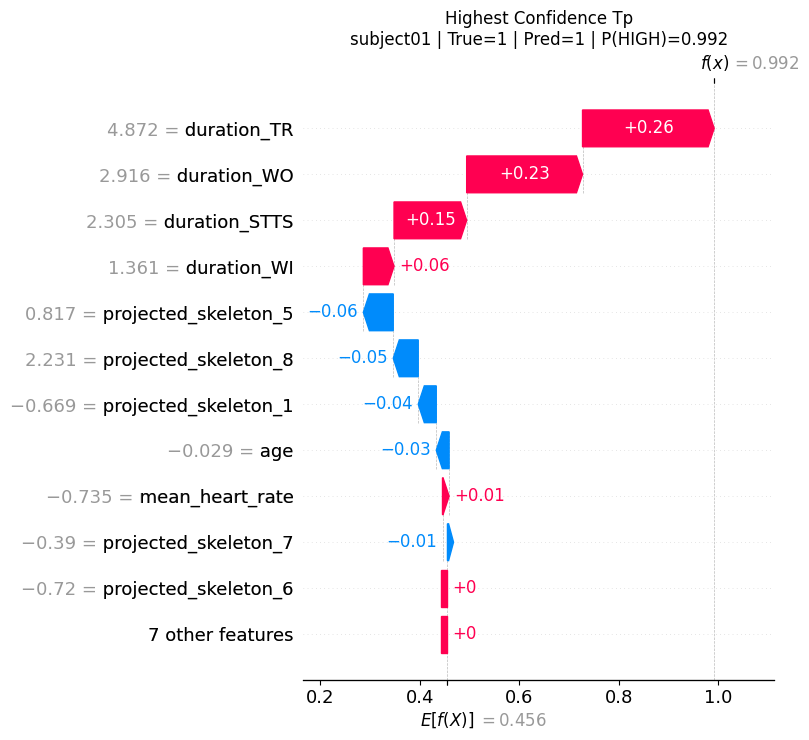

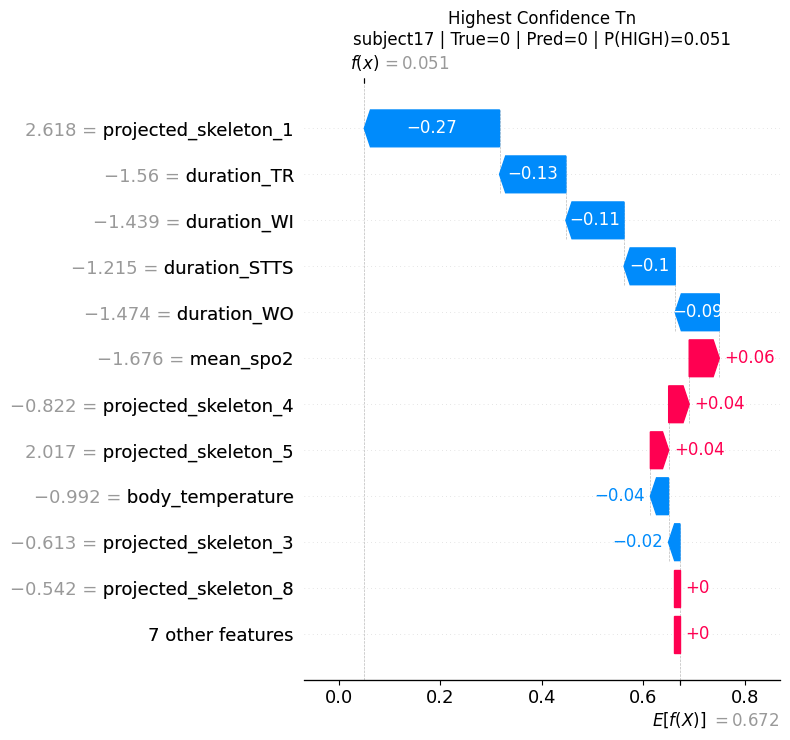

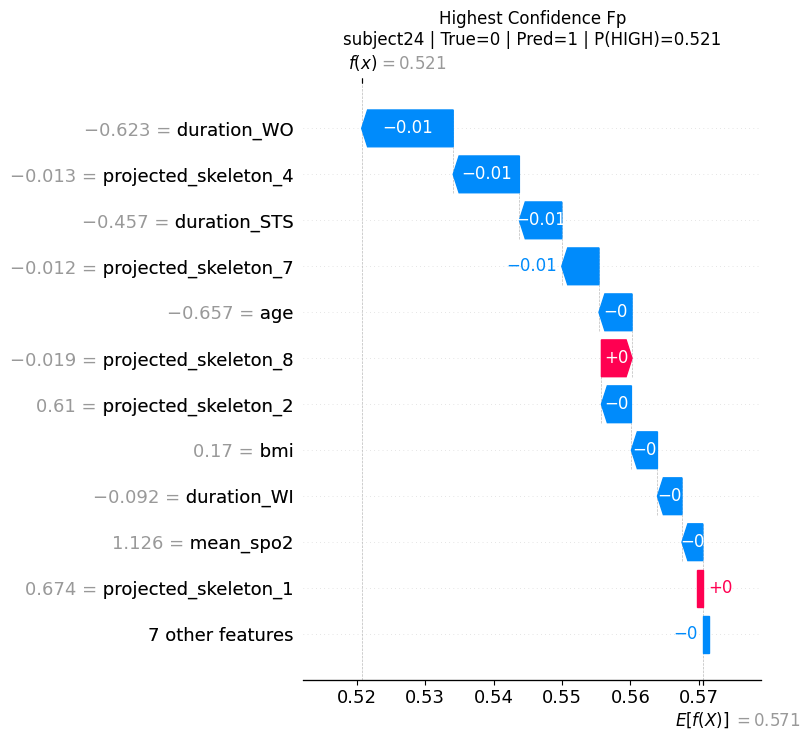

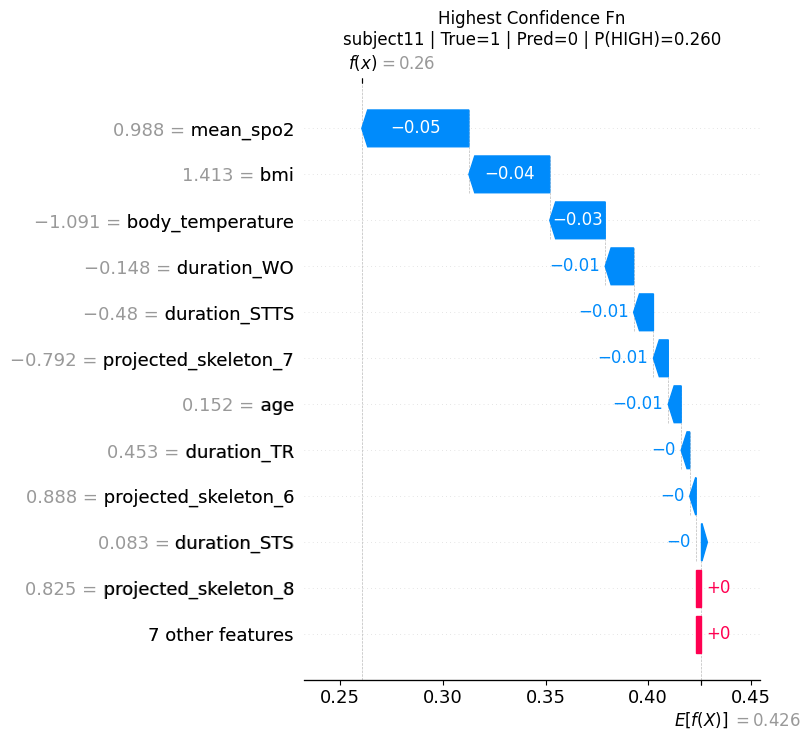

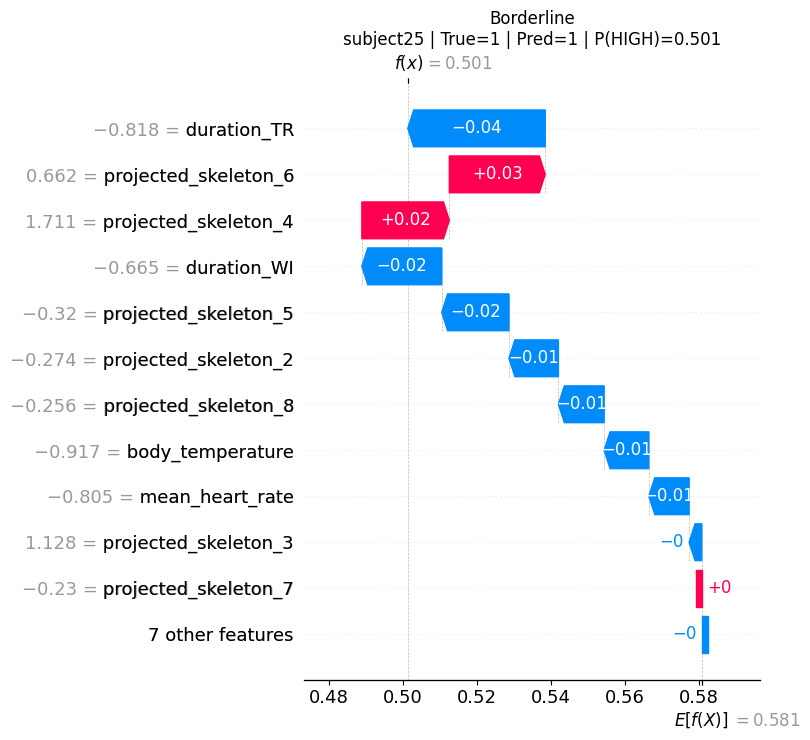

,case,subject,true_label,predicted_label,status,probability_high,top_positive_feature_1,top_positive_shap_1,top_positive_feature_2,top_positive_shap_2,top_negative_feature_1,top_negative_shap_1,top_negative_feature_2,top_negative_shap_2
0,highest_confidence_TP,subject01,1,1,TP,0.991768,duration_TR,0.264602,duration_WO,0.232870,projected_skeleton_5,-0.060123,projected_skeleton_8,-0.050237
1,highest_confidence_TN,subject17,0,0,TN,0.050692,mean_spo2,0.059266,projected_skeleton_4,0.040431,projected_skeleton_1,-0.266355,duration_TR,-0.130620
2,highest_confidence_FP,subject24,0,1,FP,0.520713,projected_skeleton_8,0.004478,duration_STTS,0.000000,duration_WO,-0.013377,projected_skeleton_4,-0.009676
3,highest_confidence_FN,subject11,1,0,FN,0.260489,duration_WI,0.000000,mean_heart_rate,0.000000,mean_spo2,-0.052146,bmi,-0.039403
4,borderline,subject25,1,1,TP,0.501316,projected_skeleton_6,0.025947,projected_skeleton_4,0.023671,duration_TR,-0.037189,duration_WI,-0.021613


In [ ]:
# ============================================================
# STEP 20: INDIVIDUAL PREDICTION EXPLANATION
#
# Selected automatically:
# - highest-confidence TP,
# - highest-confidence TN,
# - highest-confidence FP, when available,
# - highest-confidence FN, when available,
# - prediction closest to threshold.
# ============================================================

individual_dir = (
    SHAP_DIR
    / "Individual"
)

individual_dir.mkdir(
    parents=True,
    exist_ok=True,
)

individual_df = pd.DataFrame({
    "subject": subjects,
    "true_label": y,
    "probability_high": (
        oof_internal_probabilities
    ),
})

individual_df[
    "predicted_label"
] = (
    individual_df[
        "probability_high"
    ] >= THRESHOLD
).astype(int)

individual_df[
    "status"
] = np.select(
    [
        (
            individual_df[
                "true_label"
            ] == 1
        )
        & (
            individual_df[
                "predicted_label"
            ] == 1
        ),
        (
            individual_df[
                "true_label"
            ] == 0
        )
        & (
            individual_df[
                "predicted_label"
            ] == 0
        ),
        (
            individual_df[
                "true_label"
            ] == 0
        )
        & (
            individual_df[
                "predicted_label"
            ] == 1
        ),
        (
            individual_df[
                "true_label"
            ] == 1
        )
        & (
            individual_df[
                "predicted_label"
            ] == 0
        ),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN",
    ],
    default="Unknown",
)

selected_cases = {}

tp_rows = individual_df[
    individual_df["status"] == "TP"
]

if not tp_rows.empty:
    selected_cases[
        "highest_confidence_TP"
    ] = int(
        tp_rows[
            "probability_high"
        ].idxmax()
    )

tn_rows = individual_df[
    individual_df["status"] == "TN"
]

if not tn_rows.empty:
    selected_cases[
        "highest_confidence_TN"
    ] = int(
        tn_rows[
            "probability_high"
        ].idxmin()
    )

fp_rows = individual_df[
    individual_df["status"] == "FP"
]

if not fp_rows.empty:
    selected_cases[
        "highest_confidence_FP"
    ] = int(
        fp_rows[
            "probability_high"
        ].idxmax()
    )

fn_rows = individual_df[
    individual_df["status"] == "FN"
]

if not fn_rows.empty:
    selected_cases[
        "highest_confidence_FN"
    ] = int(
        fn_rows[
            "probability_high"
        ].idxmin()
    )

selected_cases[
    "borderline"
] = int(
    (
        individual_df[
            "probability_high"
        ] - THRESHOLD
    )
    .abs()
    .idxmin()
)

individual_summary_rows = []

for case_name, subject_index in (
    selected_cases.items()
):
    explanation = shap.Explanation(
        values=(
            oof_internal_shap_values[
                subject_index
            ]
        ),
        base_values=(
            oof_internal_base_values[
                subject_index
            ]
        ),
        data=(
            oof_internal_inputs[
                subject_index
            ]
        ),
        feature_names=(
            INTERNAL_FEATURE_NAMES
        ),
    )

    shap.plots.waterfall(
        explanation,
        max_display=12,
        show=False,
    )

    plt.title(
        f"{case_name.replace('_', ' ').title()}\n"
        f"{subjects[subject_index]} | "
        f"True={y[subject_index]} | "
        f"Pred="
        f"{individual_df.loc[subject_index, 'predicted_label']} | "
        f"P(HIGH)="
        f"{oof_internal_probabilities[subject_index]:.3f}"
    )

    plt.tight_layout()

    plt.savefig(
        individual_dir
        / (
            f"{case_name}_"
            f"{subjects[subject_index]}_"
            "Waterfall.png"
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    shap_row = (
        oof_internal_shap_values[
            subject_index
        ]
    )

    positive_order = np.argsort(
        shap_row
    )[::-1]

    negative_order = np.argsort(
        shap_row
    )

    individual_summary_rows.append({
        "case": case_name,
        "subject": subjects[
            subject_index
        ],
        "true_label": int(
            y[subject_index]
        ),
        "predicted_label": int(
            individual_df.loc[
                subject_index,
                "predicted_label",
            ]
        ),
        "status": individual_df.loc[
            subject_index,
            "status",
        ],
        "probability_high": float(
            oof_internal_probabilities[
                subject_index
            ]
        ),
        "top_positive_feature_1": (
            INTERNAL_FEATURE_NAMES[
                positive_order[0]
            ]
        ),
        "top_positive_shap_1": float(
            shap_row[
                positive_order[0]
            ]
        ),
        "top_positive_feature_2": (
            INTERNAL_FEATURE_NAMES[
                positive_order[1]
            ]
        ),
        "top_positive_shap_2": float(
            shap_row[
                positive_order[1]
            ]
        ),
        "top_negative_feature_1": (
            INTERNAL_FEATURE_NAMES[
                negative_order[0]
            ]
        ),
        "top_negative_shap_1": float(
            shap_row[
                negative_order[0]
            ]
        ),
        "top_negative_feature_2": (
            INTERNAL_FEATURE_NAMES[
                negative_order[1]
            ]
        ),
        "top_negative_shap_2": float(
            shap_row[
                negative_order[1]
            ]
        ),
    })

individual_explanation_summary_df = (
    pd.DataFrame(
        individual_summary_rows
    )
)

individual_explanation_summary_df.to_csv(
    individual_dir
    / "Individual_OOF_Explanation_Summary.csv",
    index=False,
)

display(
    individual_explanation_summary_df
)

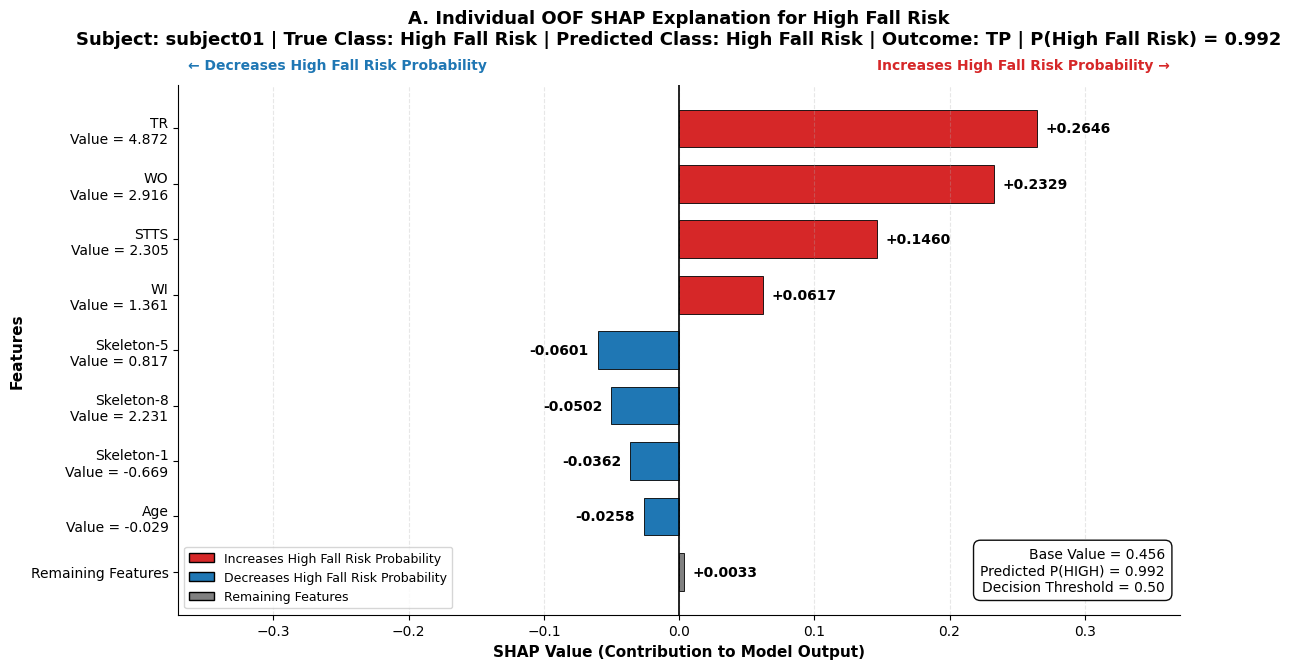

Saved figure: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Individual/Custom_Explanation/A_Custom_Individual_OOF_SHAP_High_Fall_Risk.png


,subject,panel,true_label,predicted_label,probability_high,feature,feature_value,shap_value,is_other,absolute_shap
0,subject01,A,1,1,0.991768,Remaining Features,NaN,0.003329,True,0.003329
1,subject01,A,1,1,0.991768,Age,-0.028519,-0.025813,False,0.025813
2,subject01,A,1,1,0.991768,Skeleton-1,-0.668924,-0.036226,False,0.036226
3,subject01,A,1,1,0.991768,Skeleton-8,2.231282,-0.050237,False,0.050237
4,subject01,A,1,1,0.991768,Skeleton-5,0.816534,-0.060123,False,0.060123
5,subject01,A,1,1,0.991768,WI,1.361130,0.061695,False,0.061695
6,subject01,A,1,1,0.991768,STTS,2.304593,0.146016,False,0.146016
7,subject01,A,1,1,0.991768,WO,2.915855,0.232870,False,0.232870
8,subject01,A,1,1,0.991768,TR,4.872208,0.264602,False,0.264602


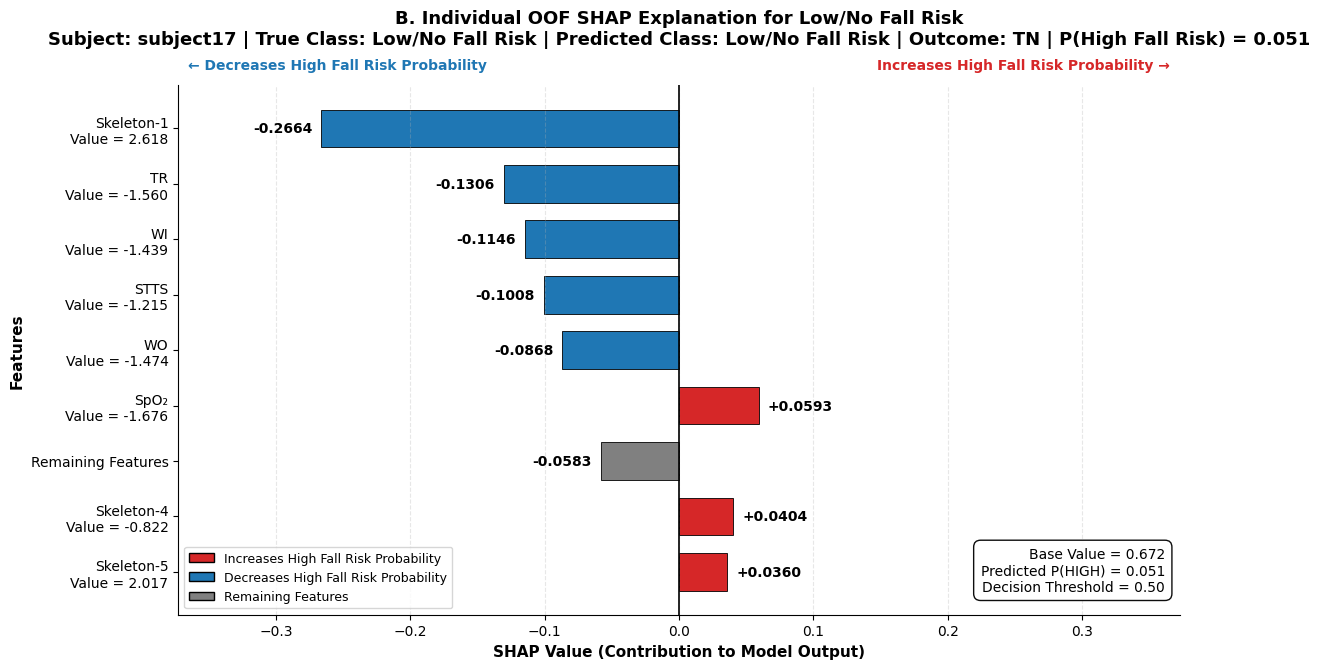

Saved figure: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Individual/Custom_Explanation/B_Custom_Individual_OOF_SHAP_Low_No_Fall_Risk.png


,subject,panel,true_label,predicted_label,probability_high,feature,feature_value,shap_value,is_other,absolute_shap
0,subject17,B,0,0,0.050692,Skeleton-5,2.017442,0.036041,False,0.036041
1,subject17,B,0,0,0.050692,Skeleton-4,-0.822295,0.040431,False,0.040431
2,subject17,B,0,0,0.050692,Remaining Features,NaN,-0.058308,True,0.058308
3,subject17,B,0,0,0.050692,SpO₂,-1.675982,0.059266,False,0.059266
4,subject17,B,0,0,0.050692,WO,-1.473798,-0.086844,False,0.086844
5,subject17,B,0,0,0.050692,STTS,-1.214664,-0.100791,False,0.100791
6,subject17,B,0,0,0.050692,WI,-1.439150,-0.114560,False,0.114560
7,subject17,B,0,0,0.050692,TR,-1.560422,-0.130620,False,0.130620
8,subject17,B,0,0,0.050692,Skeleton-1,2.618119,-0.266355,False,0.266355


CUSTOM INDIVIDUAL OOF SHAP EXPLANATION COMPLETED
Output directory: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Projection_Size_Context_Ablation_Best_Model_OOF_SHAP/05_OOF_SHAP_Best_Model/Individual/Custom_Explanation


,panel,subject,true_label,predicted_label,probability_high,status
0,A,subject01,1,1,0.991768,TP
16,B,subject17,0,0,0.050692,TN


In [ ]:
# ============================================================
# STEP 21: CUSTOM INDIVIDUAL OOF SHAP EXPLANATION
#
# Panel A:
# Highest-confidence correctly predicted High Fall Risk subject
#
# Panel B:
# Highest-confidence correctly predicted Low/No Fall Risk subject
#
# This custom visualization replaces shap.force_plot()
# to improve readability for journal publication.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TOP_N_FEATURES = 8
FIGURE_DPI = 400

HIGH_LABEL = "High Fall Risk"
LOW_LABEL = "Low/No Fall Risk"

HIGH_COLOR = "#D62728"
LOW_COLOR = "#1F77B4"
OTHER_COLOR = "#808080"


# ------------------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "subjects",
    "y",
    "THRESHOLD",
    "SHAP_DIR",
    "oof_internal_probabilities",
    "oof_internal_shap_values",
    "oof_internal_base_values",
    "oof_internal_inputs",
    "INTERNAL_FEATURE_NAMES",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are unavailable:\n- "
        + "\n- ".join(missing_variables)
        + "\n\nRun all preceding OOF SHAP cells before STEP 21."
    )


# ------------------------------------------------------------
# 3. PREPARE DATA
# ------------------------------------------------------------

subjects_array = np.asarray(
    subjects
).astype(str)

y_array = np.asarray(
    y
).astype(int).reshape(-1)

oof_probabilities = np.asarray(
    oof_internal_probabilities,
    dtype=float,
).reshape(-1)

oof_predictions = (
    oof_probabilities >= THRESHOLD
).astype(int)

oof_shap_values = np.asarray(
    oof_internal_shap_values,
    dtype=float,
)

oof_base_values = np.asarray(
    oof_internal_base_values,
    dtype=float,
).reshape(-1)

oof_inputs = np.asarray(
    oof_internal_inputs,
    dtype=float,
)

feature_names = list(
    INTERNAL_FEATURE_NAMES
)


# ------------------------------------------------------------
# 4. NORMALIZE SHAP ARRAY FORMAT
# ------------------------------------------------------------

if oof_shap_values.ndim == 3:

    if oof_shap_values.shape[-1] == 1:
        oof_shap_values = (
            oof_shap_values[:, :, 0]
        )

    elif oof_shap_values.shape[0] == 1:
        oof_shap_values = (
            oof_shap_values[0]
        )

    else:
        raise ValueError(
            "Unrecognized SHAP value format: "
            f"{oof_shap_values.shape}"
        )


# ------------------------------------------------------------
# 5. VALIDATE DIMENSIONS
# ------------------------------------------------------------

if oof_shap_values.shape != oof_inputs.shape:
    raise ValueError(
        "The SHAP value dimensions do not match "
        "the OOF input dimensions.\n"
        f"SHAP values : {oof_shap_values.shape}\n"
        f"OOF inputs  : {oof_inputs.shape}"
    )

if oof_inputs.shape[1] != len(feature_names):
    raise ValueError(
        "The number of feature names does not match "
        "the number of input columns.\n"
        f"Feature names : {len(feature_names)}\n"
        f"Input columns : {oof_inputs.shape[1]}"
    )

if len(oof_base_values) != len(y_array):
    raise ValueError(
        "The number of OOF base values does not match "
        "the number of subjects."
    )


# ------------------------------------------------------------
# 6. CREATE PREDICTION TABLE
# ------------------------------------------------------------

individual_df = pd.DataFrame({
    "subject": subjects_array,
    "true_label": y_array,
    "predicted_label": oof_predictions,
    "probability_high": oof_probabilities,
})

individual_df["status"] = np.select(
    [
        (
            individual_df["true_label"] == 1
        )
        & (
            individual_df["predicted_label"] == 1
        ),
        (
            individual_df["true_label"] == 0
        )
        & (
            individual_df["predicted_label"] == 0
        ),
        (
            individual_df["true_label"] == 0
        )
        & (
            individual_df["predicted_label"] == 1
        ),
        (
            individual_df["true_label"] == 1
        )
        & (
            individual_df["predicted_label"] == 0
        ),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN",
    ],
    default="Unknown",
)


# ------------------------------------------------------------
# 7. SELECT REPRESENTATIVE SUBJECTS
# ------------------------------------------------------------

tp_indices = np.where(
    (
        y_array == 1
    )
    & (
        oof_predictions == 1
    )
)[0]

tn_indices = np.where(
    (
        y_array == 0
    )
    & (
        oof_predictions == 0
    )
)[0]

if len(tp_indices) == 0:
    raise ValueError(
        "No True Positive case was found for Panel A."
    )

if len(tn_indices) == 0:
    raise ValueError(
        "No True Negative case was found for Panel B."
    )

high_index = int(
    tp_indices[
        np.argmax(
            oof_probabilities[
                tp_indices
            ]
        )
    ]
)

low_index = int(
    tn_indices[
        np.argmin(
            oof_probabilities[
                tn_indices
            ]
        )
    ]
)


# ------------------------------------------------------------
# 8. OUTPUT DIRECTORY
# ------------------------------------------------------------

custom_explanation_dir = (
    Path(SHAP_DIR)
    / "Individual"
    / "Custom_Explanation"
)

custom_explanation_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 9. SHORTEN FEATURE NAMES
# ------------------------------------------------------------

def shorten_feature_name(
    feature_name,
):
    """
    Convert internal feature names into concise,
    publication-friendly labels.
    """

    name = str(feature_name)

    replacements = {
        "duration_": "",
        "projected_skeleton_": "Skeleton-",
        "skeleton_projection_": "Skeleton-",
        "skel_emb_": "Skeleton-",
        "light_intensity": "Light Intensity",
        "body_temperature": "Body Temperature",
        "mean_heart_rate": "Heart Rate",
        "mean_spo2": "SpO₂",
        "bmi": "BMI",
        "temperature": "Temperature",
        "humidity": "Humidity",
        "pressure": "Pressure",
        "age": "Age",
    }

    for old_text, new_text in replacements.items():
        name = name.replace(
            old_text,
            new_text,
        )

    name = name.replace(
        "_",
        " ",
    )

    return name.strip()


# ------------------------------------------------------------
# 10. PREPARE TOP FEATURE CONTRIBUTIONS
# ------------------------------------------------------------

def prepare_contribution_data(
    subject_index,
    top_n=8,
):
    """
    Select the strongest SHAP contributions and aggregate
    all remaining contributions into 'Remaining Features'.
    """

    shap_row = np.asarray(
        oof_shap_values[
            subject_index
        ],
        dtype=float,
    )

    feature_row = np.asarray(
        oof_inputs[
            subject_index
        ],
        dtype=float,
    )

    ranked_indices = np.argsort(
        np.abs(shap_row)
    )[::-1]

    top_indices = ranked_indices[
        :top_n
    ]

    other_indices = ranked_indices[
        top_n:
    ]

    rows = []

    for feature_index in top_indices:

        rows.append({
            "feature": shorten_feature_name(
                feature_names[
                    feature_index
                ]
            ),
            "feature_value": float(
                feature_row[
                    feature_index
                ]
            ),
            "shap_value": float(
                shap_row[
                    feature_index
                ]
            ),
            "is_other": False,
        })

    if len(other_indices) > 0:

        remaining_shap = float(
            np.sum(
                shap_row[
                    other_indices
                ]
            )
        )

        rows.append({
            "feature": "Remaining Features",
            "feature_value": np.nan,
            "shap_value": remaining_shap,
            "is_other": True,
        })

    contribution_df = pd.DataFrame(
        rows
    )

    contribution_df["absolute_shap"] = (
        contribution_df[
            "shap_value"
        ].abs()
    )

    # Sort from smallest to largest so that the strongest
    # contribution appears at the top of the horizontal chart.
    contribution_df = (
        contribution_df
        .sort_values(
            "absolute_shap",
            ascending=True,
        )
        .reset_index(
            drop=True
        )
    )

    return contribution_df


# ------------------------------------------------------------
# 11. CREATE CUSTOM INDIVIDUAL EXPLANATION
# ------------------------------------------------------------

def save_custom_individual_explanation(
    subject_index,
    panel_label,
    class_title,
    file_name,
    top_n=8,
):
    """
    Create a publication-ready horizontal SHAP contribution
    plot for one out-of-fold prediction.
    """

    contribution_df = (
        prepare_contribution_data(
            subject_index=subject_index,
            top_n=top_n,
        )
    )

    base_value = float(
        oof_base_values[
            subject_index
        ]
    )

    probability = float(
        oof_probabilities[
            subject_index
        ]
    )

    prediction = int(
        oof_predictions[
            subject_index
        ]
    )

    true_label = int(
        y_array[
            subject_index
        ]
    )

    status = str(
        individual_df.loc[
            subject_index,
            "status",
        ]
    )

    predicted_class_name = (
        HIGH_LABEL
        if prediction == 1
        else LOW_LABEL
    )

    true_class_name = (
        HIGH_LABEL
        if true_label == 1
        else LOW_LABEL
    )

    # Colors indicate contribution direction.
    bar_colors = []

    for _, row in contribution_df.iterrows():

        if row["is_other"]:
            bar_colors.append(
                OTHER_COLOR
            )

        elif row["shap_value"] >= 0:
            bar_colors.append(
                HIGH_COLOR
            )

        else:
            bar_colors.append(
                LOW_COLOR
            )

    y_positions = np.arange(
        len(
            contribution_df
        )
    )

    fig, ax = plt.subplots(
        figsize=(12, 6.8)
    )

    bars = ax.barh(
        y_positions,
        contribution_df[
            "shap_value"
        ],
        color=bar_colors,
        edgecolor="black",
        linewidth=0.6,
        height=0.68,
    )

    # Zero-reference line.
    ax.axvline(
        x=0,
        linewidth=1.2,
        color="black",
    )

    # Prediction-direction annotations.
    ax.text(
        0.01,
        1.025,
        "← Decreases High Fall Risk Probability",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=LOW_COLOR,
    )

    ax.text(
        0.99,
        1.025,
        "Increases High Fall Risk Probability →",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=HIGH_COLOR,
    )

    # Feature labels.
    y_labels = []

    for _, row in contribution_df.iterrows():

        if row["is_other"]:
            label = row["feature"]

        else:
            label = (
                f"{row['feature']}\n"
                f"Value = {row['feature_value']:.3f}"
            )

        y_labels.append(
            label
        )

    ax.set_yticks(
        y_positions
    )

    ax.set_yticklabels(
        y_labels,
        fontsize=10,
    )

    # SHAP-value annotations.
    max_abs_shap = max(
        contribution_df[
            "absolute_shap"
        ].max(),
        1e-6,
    )

    label_offset = (
        max_abs_shap * 0.025
    )

    for bar, shap_value in zip(
        bars,
        contribution_df[
            "shap_value"
        ],
    ):

        if shap_value >= 0:

            x_position = (
                shap_value
                + label_offset
            )

            horizontal_alignment = (
                "left"
            )

        else:

            x_position = (
                shap_value
                - label_offset
            )

            horizontal_alignment = (
                "right"
            )

        ax.text(
            x_position,
            bar.get_y()
            + bar.get_height() / 2,
            f"{shap_value:+.4f}",
            va="center",
            ha=horizontal_alignment,
            fontsize=10,
            fontweight="bold",
        )

    # Provide sufficient horizontal margin.
    x_limit = (
        max_abs_shap * 1.40
    )

    ax.set_xlim(
        -x_limit,
        x_limit,
    )

    ax.set_xlabel(
        "SHAP Value (Contribution to Model Output)",
        fontsize=11,
        fontweight="bold",
    )

    ax.set_ylabel(
        "Features",
        fontsize=11,
        fontweight="bold",
    )

    ax.set_title(
        (
            f"{panel_label}. Individual OOF SHAP Explanation "
            f"for {class_title}\n"
            f"Subject: {subjects_array[subject_index]} | "
            f"True Class: {true_class_name} | "
            f"Predicted Class: {predicted_class_name} | "
            f"Outcome: {status} | "
            f"P(High Fall Risk) = {probability:.3f}"
        ),
        fontsize=13,
        fontweight="bold",
        pad=30,
    )

    # Prediction-summary box.
    summary_text = (
        f"Base Value = {base_value:.3f}\n"
        f"Predicted P(HIGH) = {probability:.3f}\n"
        f"Decision Threshold = {THRESHOLD:.2f}"
    )

    ax.text(
        0.985,
        0.04,
        summary_text,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox={
            "boxstyle": "round,pad=0.5",
            "facecolor": "white",
            "edgecolor": "black",
            "alpha": 0.95,
        },
    )

    legend_handles = [
        Patch(
            facecolor=HIGH_COLOR,
            edgecolor="black",
            label=(
                "Increases High Fall Risk Probability"
            ),
        ),
        Patch(
            facecolor=LOW_COLOR,
            edgecolor="black",
            label=(
                "Decreases High Fall Risk Probability"
            ),
        ),
        Patch(
            facecolor=OTHER_COLOR,
            edgecolor="black",
            label="Remaining Features",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        fontsize=9,
        frameon=True,
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.30,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    plt.tight_layout()

    output_path = (
        custom_explanation_dir
        / file_name
    )

    plt.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        pad_inches=0.25,
        facecolor="white",
    )

    plt.show()
    plt.close()

    # Save the numerical contribution table.
    contribution_output = (
        contribution_df.copy()
    )

    contribution_output.insert(
        0,
        "subject",
        subjects_array[
            subject_index
        ],
    )

    contribution_output.insert(
        1,
        "panel",
        panel_label,
    )

    contribution_output.insert(
        2,
        "true_label",
        true_label,
    )

    contribution_output.insert(
        3,
        "predicted_label",
        prediction,
    )

    contribution_output.insert(
        4,
        "probability_high",
        probability,
    )

    contribution_output.to_csv(
        custom_explanation_dir
        / file_name.replace(
            ".png",
            "_Contributions.csv",
        ),
        index=False,
    )

    print(
        "Saved figure:",
        output_path,
    )

    display(
        contribution_output
    )


# ------------------------------------------------------------
# 12. PANEL A: HIGH FALL RISK
# ------------------------------------------------------------

save_custom_individual_explanation(
    subject_index=high_index,
    panel_label="A",
    class_title=HIGH_LABEL,
    file_name=(
        "A_Custom_Individual_OOF_SHAP_"
        "High_Fall_Risk.png"
    ),
    top_n=TOP_N_FEATURES,
)


# ------------------------------------------------------------
# 13. PANEL B: LOW/NO FALL RISK
# ------------------------------------------------------------

save_custom_individual_explanation(
    subject_index=low_index,
    panel_label="B",
    class_title=LOW_LABEL,
    file_name=(
        "B_Custom_Individual_OOF_SHAP_"
        "Low_No_Fall_Risk.png"
    ),
    top_n=TOP_N_FEATURES,
)


# ------------------------------------------------------------
# 14. SAVE SELECTED SUBJECTS
# ------------------------------------------------------------

selected_cases_df = (
    individual_df.iloc[
        [
            high_index,
            low_index,
        ]
    ]
    .copy()
)

selected_cases_df.insert(
    0,
    "panel",
    [
        "A",
        "B",
    ],
)

selected_cases_df.to_csv(
    custom_explanation_dir
    / "Selected_Custom_Individual_OOF_SHAP_Cases.csv",
    index=False,
)

print("=" * 72)
print("CUSTOM INDIVIDUAL OOF SHAP EXPLANATION COMPLETED")
print("=" * 72)
print("Output directory:", custom_explanation_dir)

display(
    selected_cases_df
)

In [ ]:
# ============================================================
# STEP 22: SAVE COMPLETE OOF SHAP MATRICES AND FINAL SUMMARY
# ============================================================

shap_values_df = pd.DataFrame(
    oof_internal_shap_values,
    columns=INTERNAL_FEATURE_NAMES,
)
shap_values_df.insert(0, "subject", subjects)
shap_values_df.insert(1, "true_label", y)
shap_values_df.insert(
    2,
    "probability_high",
    oof_internal_probabilities,
)

shap_inputs_df = pd.DataFrame(
    oof_internal_inputs,
    columns=INTERNAL_FEATURE_NAMES,
)
shap_inputs_df.insert(0, "subject", subjects)

selected_prefix = (
    "Context_Aware"
    if BEST_INCLUDE_CONTEXT
    else "Baseline_Without_Context"
)

shap_values_df.to_csv(
    SHAP_TABLE_DIR
    / f"{selected_prefix}_OOF_SHAP_Values.csv",
    index=False,
)
shap_inputs_df.to_csv(
    SHAP_TABLE_DIR
    / f"{selected_prefix}_OOF_SHAP_Internal_Inputs.csv",
    index=False,
)

baseline_pooled_row = pooled_metrics_df[
    pooled_metrics_df["model"] == BASELINE_MODEL_NAME
].iloc[0]

proposed_pooled_row = pooled_metrics_df[
    pooled_metrics_df["model"] == PROPOSED_MODEL_NAME
].iloc[0]

selected_pooled_row = pooled_metrics_df[
    pooled_metrics_df["model"] == BEST_MODEL_NAME
].iloc[0]

experiment_summary = {
    "n_subjects": int(len(subjects)),
    "n_low_no": int((y == 0).sum()),
    "n_high": int((y == 1).sum()),
    "projection_sizes_tested": PROJECTION_SIZES,
    "selected_projection_dim": int(
        BEST_PROJECTION_DIM
    ),
    "validation": "Repeated LOSO",
    "random_seeds": RANDOM_SEEDS,
    "primary_seed_for_oof_shap": PRIMARY_SEED,
    "threshold": THRESHOLD,
    "selected_best_model": BEST_MODEL_NAME,
    "selected_configuration": BEST_CONFIGURATION_NAME,
    "selected_model_includes_context": BEST_INCLUDE_CONTEXT,
    "selected_fusion_dimension": BEST_FUSION_DIMENSION,
    "selected_pooled_roc_auc": float(
        selected_pooled_row["roc_auc"]
    ),
    "selected_pooled_macro_f1": float(
        selected_pooled_row["macro_f1"]
    ),
    "selected_pooled_balanced_accuracy": float(
        selected_pooled_row["balanced_accuracy"]
    ),
    "baseline_pooled_roc_auc": float(
        baseline_pooled_row["roc_auc"]
    ),
    "context_aware_pooled_roc_auc": float(
        proposed_pooled_row["roc_auc"]
    ),
    "top_global_shap_feature": str(
        global_shap_df.iloc[0]["feature"]
    ),
    "top_shap_feature_group": str(
        group_shap_df.iloc[0]["feature_group"]
    ),
    "internal_shap_feature_count": int(
        INTERNAL_FEATURE_COUNT
    ),
    "shap_feature_groups": list(
        FEATURE_GROUPS.keys()
    ),
    "result_directories": {
        "projection": str(PROJECTION_DIR),
        "baseline_without_context": str(BASELINE_DIR),
        "context_aware": str(PROPOSED_DIR),
        "comparison": str(COMPARISON_DIR),
        "oof_shap": str(SHAP_DIR),
    },
}

with open(
    OUTPUT_DIR / "Experiment_Summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        experiment_summary,
        file,
        indent=2,
    )

print("=" * 72)
print("EXPERIMENT COMPLETED")
print("=" * 72)
print(json.dumps(experiment_summary, indent=2))
print("=" * 72)
print("Results saved to:")
print(OUTPUT_DIR)


EXPERIMENT COMPLETED
{
  "n_subjects": 30,
  "n_low_no": 10,
  "n_high": 20,
  "projection_sizes_tested": [
    64,
    32,
    16,
    8
  ],
  "selected_projection_dim": 8,
  "validation": "Repeated LOSO",
  "random_seeds": [
    42,
    123,
    2026
  ],
  "primary_seed_for_oof_shap": 42,
  "threshold": 0.5,
  "selected_best_model": "MLP_Dense8_Duration_Physiological",
  "selected_configuration": "Dense-8 + Physiological + Phase Duration",
  "selected_model_includes_context": false,
  "selected_fusion_dimension": 18,
  "selected_pooled_roc_auc": 0.8999999999999999,
  "selected_pooled_macro_f1": 0.784688995215311,
  "selected_pooled_balanced_accuracy": 0.8,
  "baseline_pooled_roc_auc": 0.8999999999999999,
  "context_aware_pooled_roc_auc": 0.675,
  "top_global_shap_feature": "duration_STTS",
  "top_shap_feature_group": "Phase Duration",
  "internal_shap_feature_count": 18,
  "shap_feature_groups": [
    "Projected Skeleton",
    "Physiological",
    "Phase Duration"
  ],
  "result_di

In [ ]:
# ============================================================
# FORMAT PROJECTION-SIZE SUMMARY TABLE
# Mean ± Standard Deviation
# ============================================================
drive.mount("/content/drive")

import os
import pandas as pd

from IPython.display import display


# ------------------------------------------------------------
# 1. INPUT FILE
# ------------------------------------------------------------

INPUT_PATH = (
    "/content/Projection_Size_Summary.csv"
)

# Sesuaikan jika file berada di folder lain.


# ------------------------------------------------------------
# 2. OUTPUT FILES
# ------------------------------------------------------------

OUTPUT_DIR = os.path.dirname(
    INPUT_PATH
)

OUTPUT_CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Projection_Size_Publication_Table.csv"
)

OUTPUT_EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Projection_Size_Publication_Table.xlsx"
)


# ------------------------------------------------------------
# 3. LOAD DATA
# ------------------------------------------------------------

projection_summary_df = pd.read_csv(
    INPUT_PATH
)

print("Original table:")
display(
    projection_summary_df
)


# ------------------------------------------------------------
# 4. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "projection_dim",
    "fusion_dimension",
    "roc_auc_mean",
    "roc_auc_std",
    "pr_auc_mean",
    "pr_auc_std",
    "balanced_accuracy_mean",
    "balanced_accuracy_std",
    "macro_f1_mean",
    "macro_f1_std"
]

missing_columns = [
    column
    for column in required_columns
    if column not in projection_summary_df.columns
]

if missing_columns:
    raise ValueError(
        "Kolom berikut tidak ditemukan:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# 5. FUNCTION TO FORMAT MEAN ± SD
# ------------------------------------------------------------

def format_mean_sd(
    mean_value,
    standard_deviation,
    decimal_places=3
):
    """
    Convert mean and standard deviation into:
    mean ± standard deviation
    """

    if pd.isna(mean_value) or pd.isna(standard_deviation):
        return ""

    return (
        f"{mean_value:.{decimal_places}f} "
        f"± "
        f"{standard_deviation:.{decimal_places}f}"
    )


# ------------------------------------------------------------
# 6. CREATE PUBLICATION-READY TABLE
# ------------------------------------------------------------

publication_table_df = pd.DataFrame(
    {
        "Projection Size": (
            projection_summary_df[
                "projection_dim"
            ]
            .astype(int)
            .map(
                lambda value: f"Dense-{value}"
            )
        ),

        "Fusion Dimension": (
            projection_summary_df[
                "fusion_dimension"
            ]
            .astype(int)
        ),

        "ROC-AUC": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "roc_auc_mean"
                ],
                projection_summary_df[
                    "roc_auc_std"
                ]
            )
        ],

        "PR-AUC": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "pr_auc_mean"
                ],
                projection_summary_df[
                    "pr_auc_std"
                ]
            )
        ],

        "Balanced Accuracy": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "balanced_accuracy_mean"
                ],
                projection_summary_df[
                    "balanced_accuracy_std"
                ]
            )
        ],

        "Macro F1": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "macro_f1_mean"
                ],
                projection_summary_df[
                    "macro_f1_std"
                ]
            )
        ]
    }
)


# ------------------------------------------------------------
# 7. SORT FROM DENSE-64 TO DENSE-8
# ------------------------------------------------------------

publication_table_df[
    "_projection_numeric"
] = (
    publication_table_df[
        "Projection Size"
    ]
    .str.replace(
        "Dense-",
        "",
        regex=False
    )
    .astype(int)
)

publication_table_df = (
    publication_table_df
    .sort_values(
        by="_projection_numeric",
        ascending=False
    )
    .drop(
        columns="_projection_numeric"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. DISPLAY FINAL TABLE
# ------------------------------------------------------------

print("=" * 90)
print("PUBLICATION-READY PROJECTION-SIZE TABLE")
print("=" * 90)

display(
    publication_table_df
)


# ------------------------------------------------------------
# 9. SAVE TO CSV
# ------------------------------------------------------------

publication_table_df.to_csv(
    OUTPUT_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 10. SAVE TO EXCEL
# ------------------------------------------------------------

publication_table_df.to_excel(
    OUTPUT_EXCEL_PATH,
    index=False
)


# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("Table saved successfully.")
print()
print("CSV:")
print(OUTPUT_CSV_PATH)
print()
print("Excel:")
print(OUTPUT_EXCEL_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Original table:


,projection_dim,fusion_dimension,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,specificity_low_no_mean,specificity_low_no_std,sensitivity_high_mean,sensitivity_high_std
0,8,22,0.658333,0.059652,0.814856,0.040817,0.644444,0.050918,0.633333,0.038188,0.624922,0.037692,0.633333,0.038188,0.620053,0.043594,0.600000,0.10000,0.666667,0.104083
1,16,30,0.606667,0.091697,0.766180,0.074061,0.633333,0.000000,0.608333,0.028868,0.601870,0.019490,0.608333,0.028868,0.600274,0.020693,0.533333,0.11547,0.683333,0.057735
2,32,46,0.501667,0.131941,0.735629,0.044971,0.511111,0.153960,0.458333,0.137689,0.466613,0.126196,0.458333,0.137689,0.459788,0.134210,0.300000,0.10000,0.616667,0.189297
3,64,78,0.465000,0.168226,0.704901,0.132638,0.433333,0.100000,0.383333,0.101036,0.392056,0.092903,0.383333,0.101036,0.386001,0.097190,0.233333,0.11547,0.533333,0.104083


PUBLICATION-READY PROJECTION-SIZE TABLE


,Projection Size,Fusion Dimension,ROC-AUC,PR-AUC,Balanced Accuracy,Macro F1
0,Dense-64,78,0.465 ± 0.168,0.705 ± 0.133,0.383 ± 0.101,0.386 ± 0.097
1,Dense-32,46,0.502 ± 0.132,0.736 ± 0.045,0.458 ± 0.138,0.460 ± 0.134
2,Dense-16,30,0.607 ± 0.092,0.766 ± 0.074,0.608 ± 0.029,0.600 ± 0.021
3,Dense-8,22,0.658 ± 0.060,0.815 ± 0.041,0.633 ± 0.038,0.620 ± 0.044


Table saved successfully.

CSV:
/content/Projection_Size_Publication_Table.csv

Excel:
/content/Projection_Size_Publication_Table.xlsx
